# Промежуточная защита — версия Рифата

## Исследование и прогноз энергопотребления сталелитейного предприятия

**Цель:** по измерениям, доступным в текущий момент, спрогнозировать `Usage_kWh` на следующий 15-минутный интервал. Это задача регрессии: результатом является числовое значение энергии за интервал, а не класс нагрузки.

Ноутбук развивает исходное решение Захара: сохраняет исследование временного ряда, Feature Engineering, Random Forest, CatBoost и Optuna, но расширяет интерпретации и контроль корректности.

### Как запустить

1. Положите `Промежуточная_защита_версия_Рифата_v4.ipynb` и `Steel_industry_data.csv` в одну папку.
2. Откройте файл в JupyterLab, Jupyter Notebook или VS Code с расширением Jupyter.
3. Установите библиотеки при необходимости: `pip install pandas numpy matplotlib seaborn scikit-learn catboost optuna statsmodels nbformat`.
4. Выполните **Restart Kernel and Run All** сверху вниз. Не запускайте шаги моделирования отдельно от предшествующих шагов: они используют рассчитанные ранее признаки и переменные.

## Навигация по исследованию

| Раздел | Шаги | Содержание |
|---|---:|---|
| Аудит и подготовка исходных данных | 01–08 | Загрузка, структура, качество, восстановление временной шкалы |
| Разведочный анализ (EDA) | 09–17 | Распределения, динамика, выбросы, календарь и автокорреляция |
| Feature Engineering | 18–26 | Целевая переменная, календарные/лаговые признаки, контроль утечек и разделение |
| Обучение и выбор модели | 27–34 | Метрики, baseline, Random Forest, CatBoost, Optuna, временная CV и тест |
| Диагностика и итоги | 35–39 | График прогноза, остатки, ошибки на пиках, важность признаков и итог |

---

### Как устроены шаги

Каждый из 39 шагов отвечает на отдельный вопрос. Расчёты и графики остаются в кодовых ячейках, а интерпретации оформлены отдельными **Markdown-ячейками**: так пояснения читаются как часть аналитического отчёта, а не как технический вывод Python. Не каждый график получает отдельный вывод: несколько связанных визуализаций объединены одной интерпретацией внутри соответствующего шага.

**Важно:** численные интерпретации относятся к приложенному `Steel_industry_data.csv`. Если заменить исходный CSV или существенно изменить расчёты, численные выводы нужно пересчитать и обновить.

**Единицы измерения:** `Usage_kWh` — энергия, потреблённая за один 15-минутный интервал, в кВт·ч. Это не мгновенная мощность в кВт. Поэтому MAE и RMSE далее также выражаются в кВт·ч на один интервал.

## Шаг 01. Импорт библиотек и настройка воспроизводимости

Подключаем инструменты для табличного анализа, графиков, временной валидации и моделей. Фиксируем `SEED`, чтобы случайные процедуры (например, Random Forest и Optuna) можно было воспроизвести при повторном запуске.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    TimeSeriesSplit, RandomizedSearchCV, cross_validate
)
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

from catboost import CatBoostRegressor
import optuna

# Фиксируем параметры случайных алгоритмов для повторяемости эксперимента.
SEED = 42
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 30)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print('Библиотеки загружены. SEED =', SEED)
import sklearn, catboost
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scikit-learn:', sklearn.__version__)
print('CatBoost:', catboost.__version__, '| Optuna:', optuna.__version__)

from IPython.display import display


Библиотеки загружены. SEED = 42
pandas: 2.2.3 | numpy: 2.3.5 | scikit-learn: 1.8.0
CatBoost: 1.2.8 | Optuna: 4.8.0


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Результат шага 01 — среда готова

> **Проверка выполнена:** основные библиотеки для анализа, визуализации, временной валидации и моделирования успешно подключены.

Используются `pandas 2.2.3`, `NumPy 2.3.5`, `scikit-learn 1.8.0`, `CatBoost 1.2.8` и `Optuna 4.8.0`. Случайное зерно `SEED = 42` фиксирует случайные операции в коде и делает повторный запуск более воспроизводимым при той же версии библиотек и сопоставимой вычислительной среде.

**Что важно:** настройка среды ещё ничего не говорит о качестве исходных данных. Далее отдельно проверяются структура, пропуски, дубликаты и непрерывность временного ряда.

## Шаг 02. Загрузка исходного CSV

Читаем файл и сразу проверяем обязательные поля. Это защищает дальнейшие шаги от ситуации, когда файл не найден, названия колонок отличаются или загружен не тот набор данных.

In [2]:
DATA_FILE = Path('Steel_industry_data.csv')

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Файл {DATA_FILE} не найден. Поместите CSV в ту же папку, что и ноутбук. "
        f"Текущая папка: {Path.cwd()}"
    )

df = pd.read_csv(DATA_FILE)

required_columns = [
    'date', 'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type'
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f'В CSV отсутствуют обязательные столбцы: {missing_columns}')

print(f'Файл загружен: {DATA_FILE.resolve()}')
print(f'Размер датасета: {df.shape[0]:,} строк × {df.shape[1]} столбцов')
display(df.head())

Файл загружен: /mnt/data/Steel_industry_data.csv
Размер датасета: 35,040 строк × 11 столбцов


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


### Результат шага 02 — исходный файл загружен

> **Загружено 35 040 строк и 11 столбцов.** Обязательные поля для анализа и прогноза найдены.

Одна строка содержит измерения и сопутствующие признаки для одного 15-минутного интервала. При 96 интервалах в сутки 35 040 строк соответствуют 365 суткам наблюдений.

**Как это понимать:** объём данных достаточен для изучения суточных и недельных повторений, а также для разделения истории на обучающий и более поздний тестовый периоды. Однако сам факт успешного чтения CSV не подтверждает правильность времени или отсутствие ошибок измерения — это проверяется отдельно.

## Шаг 03. Паспорт датасета и смысл переменных

Перед расчётами важно понимать, что означает каждый столбец. В частности, `Usage_kWh` — целевая переменная, `NSM` — число секунд от полуночи, а `Load_Type` — категориальная метка режима нагрузки. Точные физические выводы о способе расчёта CO₂ из одного названия столбца сделать нельзя.

In [3]:
display(pd.DataFrame([
    ('date', 'Дата и время исходного измерения', 'временная метка'),
    ('Usage_kWh', 'Активная энергия, потреблённая за интервал', 'кВт·ч'),
    ('Lagging_Current_Reactive.Power_kVarh', 'Отстающая реактивная энергия', 'кВАр·ч'),
    ('Leading_Current_Reactive_Power_kVarh', 'Опережающая реактивная энергия', 'кВАр·ч'),
    ('CO2(tCO2)', 'Показатель CO₂ в исходном датасете; метод расчёта не раскрыт в CSV', 'единица по источнику'),
    ('Lagging_Current_Power_Factor', 'Коэффициент мощности для отстающего режима', '%'),
    ('Leading_Current_Power_Factor', 'Коэффициент мощности для опережающего режима', '%'),
    ('NSM', 'Число секунд от полуночи', 'секунды'),
    ('WeekStatus', 'Признак буднего/выходного дня', 'категория'),
    ('Day_of_week', 'День недели', 'категория'),
    ('Load_Type', 'Категория нагрузки: Light / Medium / Maximum', 'категория')
], columns=['Столбец', 'Смысл', 'Единица / формат']))

,Столбец,Смысл,Единица / формат
0,date,Дата и время исходного измерения,временная метка
1,Usage_kWh,"Активная энергия, потреблённая за интервал",кВт·ч
2,Lagging_Current_Reactive.Power_kVarh,Отстающая реактивная энергия,кВАр·ч
3,Leading_Current_Reactive_Power_kVarh,Опережающая реактивная энергия,кВАр·ч
4,CO2(tCO2),Показатель CO₂ в исходном датасете; метод расч...,единица по источнику
5,Lagging_Current_Power_Factor,Коэффициент мощности для отстающего режима,%
6,Leading_Current_Power_Factor,Коэффициент мощности для опережающего режима,%
7,NSM,Число секунд от полуночи,секунды
8,WeekStatus,Признак буднего/выходного дня,категория
9,Day_of_week,День недели,категория


### Что можно изучить по составу данных

В таблице есть несколько групп переменных:

| Группа | Поля | Для чего нужны |
|---|---|---|
| Целевая переменная | `Usage_kWh` | Энергия, потреблённая за 15-минутный интервал; её прогнозируем |
| Электрические показатели | реактивная энергия и `Power_Factor` | Описывают электрический режим и сопутствуют изменению нагрузки |
| Показатель CO₂ | `CO2(tCO2)` | Проверяем статистическую и прогнозную связь; метод расчёта в CSV не раскрыт |
| Время | `date`, `NSM` | Задают момент наблюдения и время суток |
| Категории | `WeekStatus`, `Day_of_week`, `Load_Type` | Описывают календарный день и класс текущей нагрузки |

**Важное ограничение данных:** в наборе нет идентификаторов отдельных печей, производственных заказов, журналов переключения оборудования и тарифных периодов. Поэтому по этим данным можно обнаруживать закономерности энергопотребления, но нельзя достоверно назвать конкретную печь или технологическую операцию причиной отдельного пика.

`Load_Type` — категориальная метка, а не числовое значение потребления. `CO2(tCO2)` также нельзя автоматически трактовать как будущий прогноз выбросов: мы анализируем только то, что реально содержится в текущем столбце.

## Шаг 04. Размер таблицы, названия столбцов и типы данных

Смотрим, сколько строк и столбцов загружено, как pandas распознал типы и нет ли полей, прочитанных как текст вместо чисел. Это влияет на расчёты статистик, корреляций и работу моделей.

In [4]:
print('Размер датасета:', df.shape)
print('\nНазвания столбцов:')
print(df.columns.tolist())
print('\nИнформация о датасете:')
df.info()

Размер датасета: (35040, 11)

Названия столбцов:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-n

### Результат шага 04 — структура таблицы понятна

В датасете **35 040 строк и 11 столбцов**: pandas распознал **7 числовых** и **4 нечисловых** поля. Дата на этом этапе прочитана как текстовая строка, поэтому её ещё нельзя безопасно использовать для расчёта временных интервалов и лагов.

**Почему это важно:** тип данных определяет доступные операции. Числовые поля можно анализировать статистически; категориальные нужно кодировать для большинства моделей `scikit-learn`, тогда как CatBoost умеет работать с категориальными полями напрямую. Дату необходимо преобразовать в `datetime`, но затем отдельно проверить реальную последовательность времени.

## Шаг 05. Пропуски, дубликаты и допустимые категории

Проверяем пустые ячейки и полностью повторяющиеся строки. Дополнительно смотрим, какие значения встретились в `WeekStatus`, `Day_of_week` и `Load_Type`: неожиданные написания могут создать отдельные ложные категории.

In [5]:
missing_by_column = df.isna().sum().rename('Пропусков').to_frame()
display(missing_by_column)

print('Всего пропущенных значений:', int(df.isna().sum().sum()))
print('Количество полных дубликатов:', int(df.duplicated().sum()))

# Категориальные значения и их частоты помогают проверить ожидаемые классы.
for column in ['WeekStatus', 'Day_of_week', 'Load_Type']:
    print(f'\n{column}:')
    print(df[column].value_counts(dropna=False).to_string())

,Пропусков
date,0
Usage_kWh,0
Lagging_Current_Reactive.Power_kVarh,0
Leading_Current_Reactive_Power_kVarh,0
CO2(tCO2),0
Lagging_Current_Power_Factor,0
Leading_Current_Power_Factor,0
NSM,0
WeekStatus,0
Day_of_week,0


Всего пропущенных значений: 0
Количество полных дубликатов: 0

WeekStatus:
WeekStatus
Weekday    25056
Weekend     9984

Day_of_week:
Day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992

Load_Type:
Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272


In [6]:
missing_total = int(df.isna().sum().sum())
duplicates_total = int(df.duplicated().sum())

### Вывод по шагу 05 — базовые проверки качества

| Проверка | Результат | Интерпретация |
|---|---:|---|
| Пропущенные ячейки | **0** | Не требуется заполнять пустые значения на этом этапе |
| Полные дубликаты строк | **0** | Нет полностью повторяющихся записей |
| `Load_Type` | 3 ожидаемых класса | `Light_Load`, `Medium_Load`, `Maximum_Load` |
| `WeekStatus` | 2 класса | Будний день и выходной |

**Что означают эти результаты:** таблица не содержит явных пропусков и полных копий строк. Это хорошо для подготовки данных, но не доказывает безошибочность измерений: датчик может записать необычное, но непустое значение, а временная метка может быть некорректной. Поэтому дальше отдельно проверяем временную непрерывность и статистически редкие значения.

Одинаковое энергопотребление в двух разных моментах времени не является дубликатом: дубликатом считается полное совпадение всех полей строки.

## Шаг 06. Описательная статистика: среднее, медиана и процентили

Таблица `describe()` показывает центральные значения и разброс. Для `Usage_kWh` отдельно разберём среднее, медиану, стандартное отклонение, квартили и верхние процентили — эти показатели отвечают на разные вопросы и не должны трактоваться как взаимозаменяемые.

In [7]:
descriptive = df.describe(include='all').T
display(descriptive)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,35040,35040,01/01/2018 00:15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Usage_kWh,35040.0,NaN,NaN,NaN,27.386892,33.44438,0.0,3.2,4.57,51.2375,157.18
Lagging_Current_Reactive.Power_kVarh,35040.0,NaN,NaN,NaN,13.035384,16.306,0.0,2.3,5.0,22.64,96.91
Leading_Current_Reactive_Power_kVarh,35040.0,NaN,NaN,NaN,3.870949,7.424463,0.0,0.0,0.0,2.09,27.76
CO2(tCO2),35040.0,NaN,NaN,NaN,0.011524,0.016151,0.0,0.0,0.0,0.02,0.07
Lagging_Current_Power_Factor,35040.0,NaN,NaN,NaN,80.578056,18.921322,0.0,63.32,87.96,99.0225,100.0
Leading_Current_Power_Factor,35040.0,NaN,NaN,NaN,84.36787,30.456535,0.0,99.7,100.0,100.0,100.0
NSM,35040.0,NaN,NaN,NaN,42750.0,24940.534317,0.0,21375.0,42750.0,64125.0,85500.0
WeekStatus,35040,2,Weekday,25056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_week,35040,7,Monday,5088,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
u = df['Usage_kWh']
mean_u = float(u.mean())
median_u = float(u.median())
std_u = float(u.std())
p90_u, p95_u, p99_u = [float(u.quantile(q)) for q in (0.90, 0.95, 0.99)]
max_u = float(u.max())

In [9]:
q1_u, q3_u = u.quantile([0.25, 0.75])
cv_u = std_u / mean_u if mean_u else np.nan

### Вывод по шагу 06 — потребление сильно неоднородно

| Показатель `Usage_kWh` | Значение | Что показывает |
|---|---:|---|
| Среднее | **27,39 кВт·ч** | Арифметический уровень по всем интервалам |
| Медиана | **4,57 кВт·ч** | Центральное наблюдение: половина значений ниже, половина выше |
| Стандартное отклонение | **33,44 кВт·ч** | Масштаб разброса; сильно реагирует на большие значения |
| Q1 / Q3 | **3,20 / 51,24 кВт·ч** | Границы центральных 50% наблюдений |
| P90 / P95 / P99 | **78,08 / 99,04 / 122,71 кВт·ч** | Уровни, ниже которых находится соответственно 90%, 95% и 99% наблюдений |
| Максимум | **157,18 кВт·ч** | Наибольшее единичное значение |

**Главный результат:** среднее примерно в **6 раз выше медианы**. Это значит, что типичный интервал потребляет сравнительно мало энергии, но редкие крупные значения заметно поднимают среднее. Стандартное отклонение (33,44) даже больше среднего (27,39), что подтверждает высокую изменчивость ряда.

P99 = 122,71 кВт·ч означает, что примерно 99% 15-минутных наблюдений не превышают этот уровень, а около 1% находятся выше. Максимум 157,18 кВт·ч характеризует только самый высокий интервал и не показывает частоту подобных событий.

**Следствие для анализа:** одного среднего недостаточно. Нужно смотреть форму распределения, временные пики и качество прогноза отдельно на высоких нагрузках. Стандартное отклонение само по себе не является признаком неисправности датчика.

## Шаг 07. Восстановление правильной временной шкалы

В исходной последовательности строк полночь (`NSM = 0`) записана последней строкой своего исходного дня. Если оставить дату без коррекции и отсортировать, запись 00:00 окажется перед 00:15 того же дня, хотя по последовательности измерений она относится к началу следующих суток. Исправляем это до расчёта лагов.

In [10]:
# Восстанавливаем непрерывную временную шкалу.
# В исходном CSV записи идут по 15 минут, однако строка NSM == 0
# стоит в конце соответствующего дня и имеет дату этого же дня.
# Для этой строки фактическая временная отметка — полночь следующего дня.

df['date_source'] = pd.to_datetime(
    df['date'], format='%d/%m/%Y %H:%M', errors='raise'
)
df['source_day'] = df['date_source'].dt.normalize()
midnight_rows = df['NSM'].eq(0)
df['date'] = df['date_source'] + pd.to_timedelta(
    midnight_rows.astype('int8'), unit='D'
)

# После коррекции сортируем по восстановленной временной отметке.
df = df.sort_values('date', kind='stable').reset_index(drop=True)

# Исходные Day_of_week и WeekStatus также относятся к дате до переноса
# строки NSM == 0. Пересчитываем их по фактической временной отметке.
df['Day_of_week'] = df['date'].dt.day_name()
df['WeekStatus'] = np.where(df['date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')

intervals = df['date'].diff().dropna()
expected_step = pd.Timedelta(minutes=15)
seconds_from_midnight = (
    df['date'].dt.hour * 3600
    + df['date'].dt.minute * 60
    + df['date'].dt.second
)

print('Тип даты:', df['date'].dtype)
print('Исходных строк с NSM = 0, перенесённых на следующие сутки:', int(midnight_rows.sum()))
print('Период восстановленного ряда:', df['date'].min(), '—', df['date'].max())
print('Уникальных временных отметок:', df['date'].nunique())
print('Количество шагов, отличных от 15 минут:', int((intervals != expected_step).sum()))
print('Несовпадений времени с NSM:', int((seconds_from_midnight != df['NSM']).sum()))

assert df['date'].is_monotonic_increasing, 'Временной ряд не упорядочен.'
assert df['date'].is_unique, 'Обнаружены повторяющиеся временные отметки.'
assert (intervals == expected_step).all(), 'Временной ряд содержит пропущенные или лишние интервалы.'
assert (seconds_from_midnight == df['NSM']).all(), 'NSM не совпадает со временем суток.'

print('Проверка пройдена: 35 040 измерений образуют непрерывный ряд с шагом 15 минут.')
display(df.loc[df['NSM'].eq(0), ['date_source', 'date', 'NSM', 'Day_of_week', 'WeekStatus']].head())

Тип даты: datetime64[ns]
Исходных строк с NSM = 0, перенесённых на следующие сутки: 365
Период восстановленного ряда: 2018-01-01 00:15:00 — 2019-01-01 00:00:00
Уникальных временных отметок: 35040
Количество шагов, отличных от 15 минут: 0
Несовпадений времени с NSM: 0
Проверка пройдена: 35 040 измерений образуют непрерывный ряд с шагом 15 минут.


,date_source,date,NSM,Day_of_week,WeekStatus
95,2018-01-01,2018-01-02,0,Tuesday,Weekday
191,2018-01-02,2018-01-03,0,Wednesday,Weekday
287,2018-01-03,2018-01-04,0,Thursday,Weekday
383,2018-01-04,2018-01-05,0,Friday,Weekday
479,2018-01-05,2018-01-06,0,Saturday,Weekend


### Вывод по шагу 07 — временную шкалу необходимо было восстановить

В исходных данных обнаружено **365 строк с `NSM = 0`**. Каждая такая строка обозначает полночь, но в CSV она расположена в конце блока записей исходного дня и имеет дату этого же дня. Для корректной временной последовательности эти записи перенесены на следующие сутки.

После исправления период наблюдений: **01.01.2018 00:15 — 01.01.2019 00:00**. `Day_of_week` и `WeekStatus` пересчитаны по восстановленной временной метке.

**Почему это принципиально:** лаг в 96 строк должен означать ровно 24 часа, а лаг в 672 строки — ровно 7 суток. Если полночь оставить не на своём месте, значения «сутки назад» и календарные признаки будут соответствовать неправильным моментам времени. Это исказит признаки ещё до обучения модели.

## Шаг 08. Проверка непрерывности 15-минутного ряда

После коррекции проверяем три условия: временные метки уникальны, отсортированы, а разница между соседними наблюдениями везде равна 15 минутам. Дополнительно сверяем время суток с `NSM` — это независимая проверка корректности временного поля.

In [11]:
n_points = len(df)
expected_intervals = n_points - 1
non_15 = int((df['date'].diff().dropna() != pd.Timedelta(minutes=15)).sum())

### Вывод по шагу 08 — временной ряд непрерывен

| Контроль | Результат |
|---|---:|
| Наблюдений | **35 040** |
| Межстрочных интервалов | **35 039** |
| Интервалов не по 15 минут | **0** |
| Повторяющихся временных меток | **0** |
| Несовпадений времени с `NSM` | **0** |
| Хронологический порядок | **Соблюдён** |

**Что это означает:** после переноса полуночных записей каждая следующая строка соответствует следующему 15-минутному интервалу. Временные метки уникальны, отсортированы, а время суток совпадает с независимым полем `NSM`.

Это подтверждает, что временные лаги можно интерпретировать как фиксированные периоды: 4 строки — час, 96 — сутки, 672 — неделя. Если бы здесь обнаружились пропуски или скачки времени, сначала требовалось бы исследовать их, а уже потом строить лаговые признаки.

## Шаг 09. Распределение целевой переменной Usage_kWh

Гистограмма показывает, где сосредоточено большинство измерений и насколько длинен хвост больших значений. Вертикальные линии среднего и медианы помогают увидеть асимметрию; ниже отдельно объясняем нули и процентили.

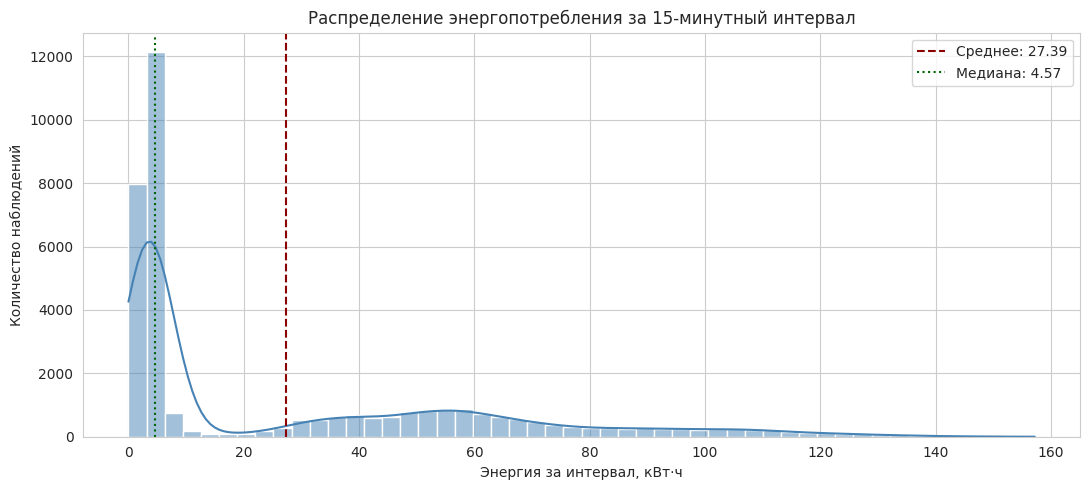

Среднее: 27.39 кВт·ч; медиана: 4.57 кВт·ч


In [12]:
plt.figure(figsize=(11, 5))
sns.histplot(df['Usage_kWh'], bins=50, kde=True, color='steelblue')
mean_usage = df['Usage_kWh'].mean()
median_usage = df['Usage_kWh'].median()
plt.axvline(mean_usage, color='darkred', linestyle='--', label=f'Среднее: {mean_usage:.2f}')
plt.axvline(median_usage, color='darkgreen', linestyle=':', label=f'Медиана: {median_usage:.2f}')
plt.title('Распределение энергопотребления за 15-минутный интервал')
plt.xlabel('Энергия за интервал, кВт·ч')
plt.ylabel('Количество наблюдений')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Среднее: {mean_usage:.2f} кВт·ч; медиана: {median_usage:.2f} кВт·ч')

In [13]:
zero_count = int((u == 0).sum())
skew_u = float(u.skew())
ratio_mean_median = mean_usage / median_usage if median_usage else np.nan

### Вывод по шагу 09 — распределение имеет длинный правый хвост

Среднее `Usage_kWh` равно **27,39 кВт·ч**, медиана — **4,57 кВт·ч**. Среднее в 6 раз больше медианы, а коэффициент асимметрии (`skewness`) равен **+1,20**.

**Как читать эти показатели:** положительная асимметрия означает, что распределение имеет более длинный хвост в сторону больших значений. Большинство интервалов находится в сравнительно низкой области, но редкие высокие нагрузки заметно влияют на среднее.

В данных найден **1 нулевой интервал**. Это важно для выбора метрик: MAPE делит ошибку на фактическое значение и становится неопределённой при нуле и нестабильной около нуля. Поэтому для оценки прогноза далее используем прежде всего MAE и RMSE.

P99 составляет **122,71 кВт·ч**, максимум — **157,18 кВт·ч**. Высокие значения не удаляем только из-за того, что они редкие: они могут быть реальными режимами предприятия. Модель будет проверяться и на обычных интервалах, и отдельно на высоких нагрузках.

## Шаг 10. Динамика потребления во времени и дневные итоги

График 15-минутных значений показывает внутрисуточные колебания и высокие пики. Дневная сумма собирает 96 значений в одно число, а недельное скользящее среднее сглаживает колебания между днями. Эти масштабы отвечают на разные вопросы.

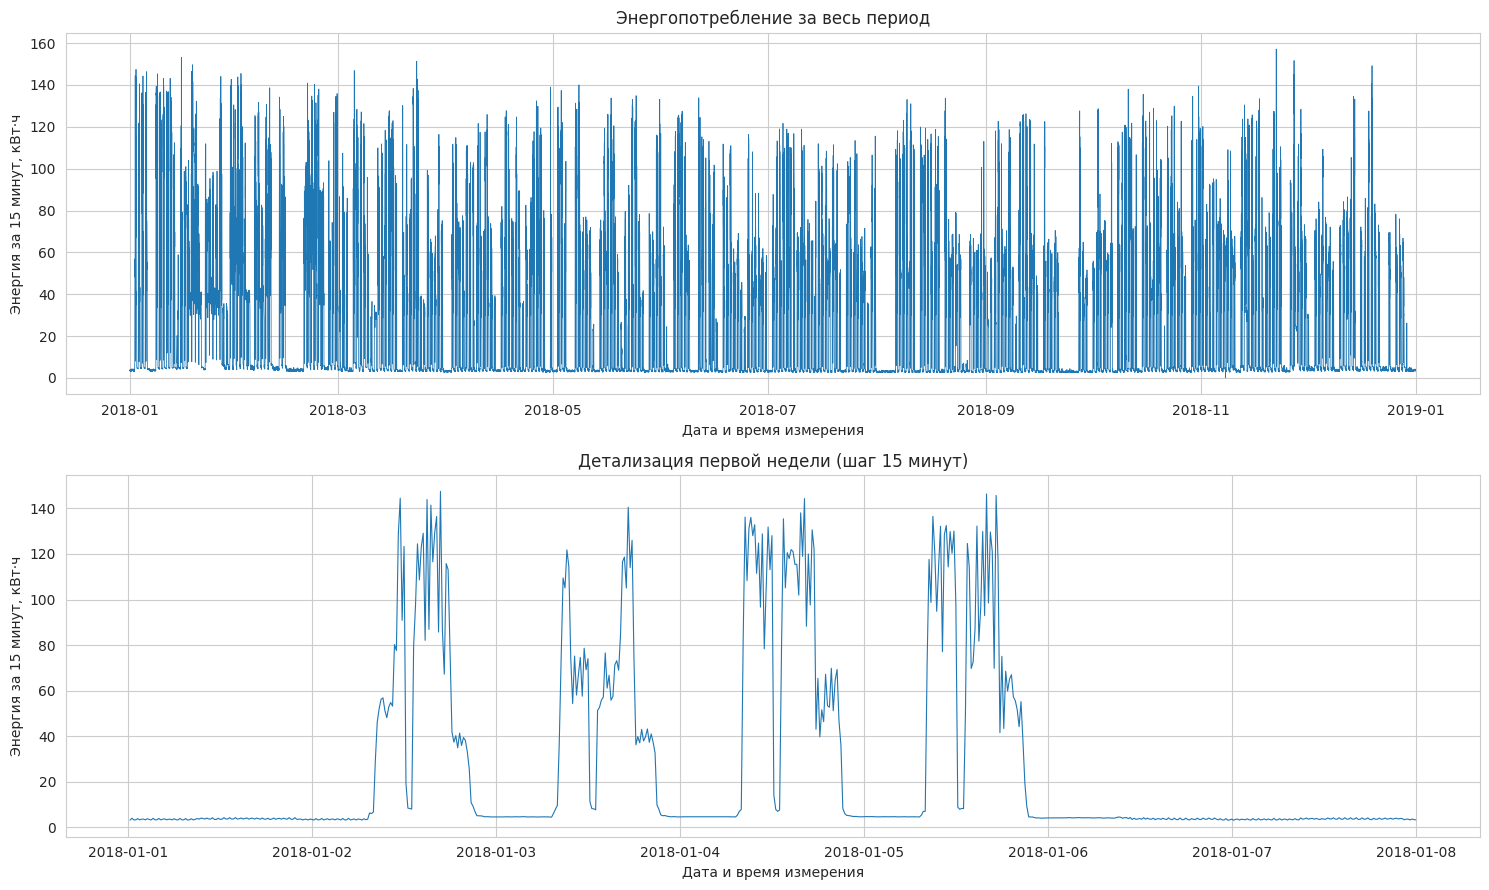

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(df['date'], df['Usage_kWh'], linewidth=0.55)
axes[0].set_title('Энергопотребление за весь период')
axes[0].set_xlabel('Дата и время измерения')
axes[0].set_ylabel('Энергия за 15 минут, кВт·ч')

# Первые семь суток: 7 × 96 измерений.
week_sample = df.iloc[:7 * 96]
axes[1].plot(week_sample['date'], week_sample['Usage_kWh'], linewidth=0.8)
axes[1].set_title('Детализация первой недели (шаг 15 минут)')
axes[1].set_xlabel('Дата и время измерения')
axes[1].set_ylabel('Энергия за 15 минут, кВт·ч')

plt.tight_layout()
plt.show()

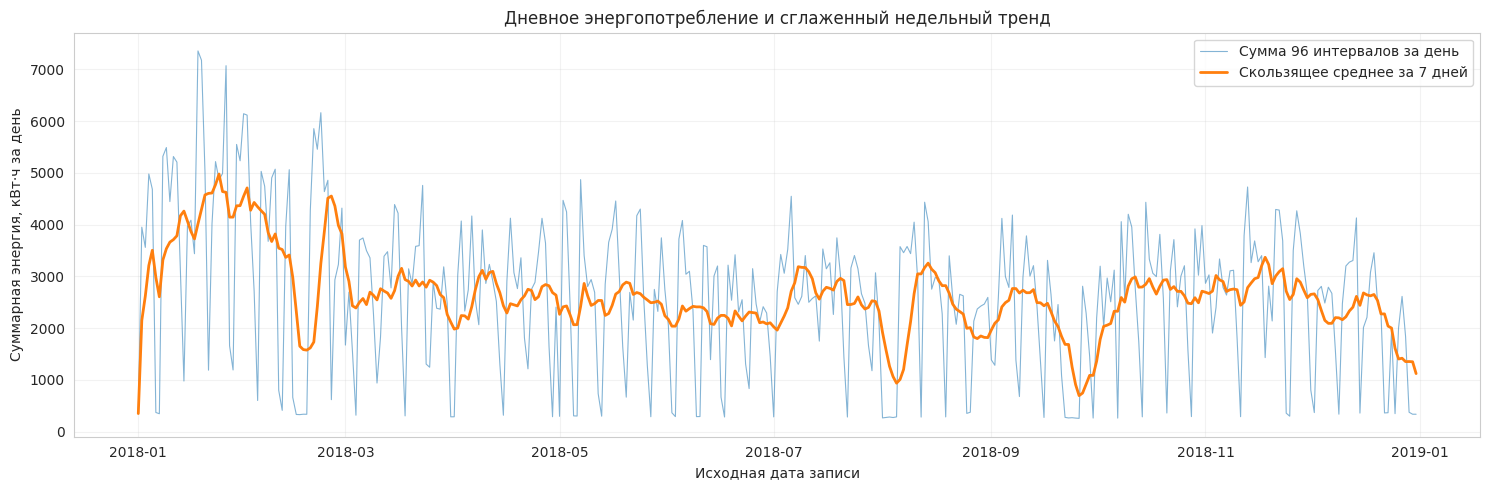

In [15]:
daily_profile = df.groupby('source_day').agg(
    daily_energy_kwh=('Usage_kWh', 'sum'),
    intervals=('Usage_kWh', 'size')
).sort_index()
daily_profile['rolling_7d'] = daily_profile['daily_energy_kwh'].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_profile.index, daily_profile['daily_energy_kwh'],
        linewidth=0.8, alpha=0.55, label='Сумма 96 интервалов за день')
ax.plot(daily_profile.index, daily_profile['rolling_7d'],
        linewidth=2, label='Скользящее среднее за 7 дней')
ax.set_title('Дневное энергопотребление и сглаженный недельный тренд')
ax.set_xlabel('Исходная дата записи')
ax.set_ylabel('Суммарная энергия, кВт·ч за день')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

max_day = daily_profile['daily_energy_kwh'].idxmax()
min_day = daily_profile['daily_energy_kwh'].idxmin()

### Вывод по шагу 10 — уровень потребления заметно меняется во времени

Зафиксировано **365 исходных календарных дней**, в каждом — ровно **96 интервалов**. Дневная сумма складывает энергию всех 96 измерений и показывает общий объём потребления за сутки; это не то же самое, что значение одного 15-минутного интервала.

| Дневной показатель | Значение |
|---|---:|
| Наибольшая дневная сумма | **7 353,84 кВт·ч** — 18.01.2018 |
| Наименьшая дневная сумма | **259,46 кВт·ч** — 26.09.2018 |

Максимальный дневной итог примерно в **28,3 раза** выше минимального. Это большой разрыв: он может отражать существенное различие в режиме работы предприятия, остановку/снижение производства или иной фактор. Сам график не позволяет установить причину — для этого потребовались бы производственные журналы.

Тонкая линия показывает отдельные дневные суммы и реагирует на изменения между днями. Семидневное скользящее среднее сглаживает колебания и помогает увидеть более длительный тренд. Сглаженная линия не отменяет краткосрочные пики внутри дня; для них сохраняем 15-минутный график.

## Шаг 11. Выбросы: boxplot и количественное правило IQR

Boxplot показывает медиану, центральные 50% значений и наблюдения за условными границами. В качестве количественного правила используем 1,5 межквартильного размаха: `IQR = Q3 − Q1`. Этот метод помечает статистически редкие значения, но не определяет, является ли запись ошибкой.

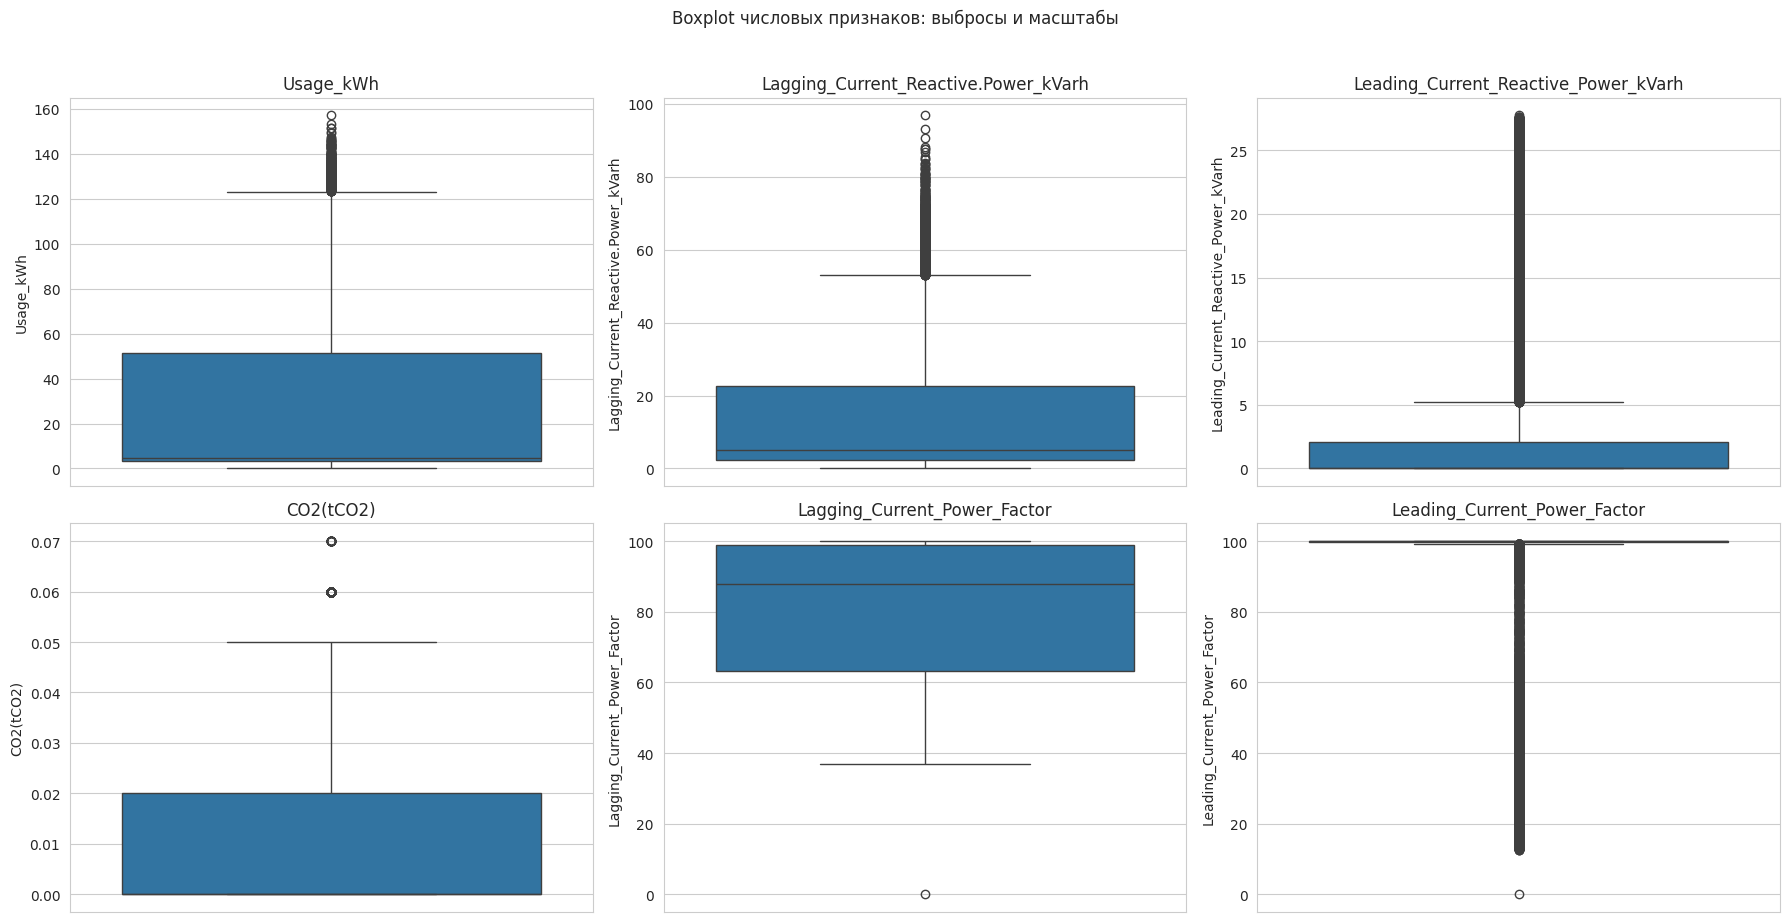

In [16]:
numeric_cols_eda = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), numeric_cols_eda):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle('Boxplot числовых признаков: выбросы и масштабы', y=1.02)
plt.tight_layout()
plt.show()

In [17]:
outlier_rows = []
for column in numeric_cols_eda:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    mask = (df[column] < lower_bound) | (df[column] > upper_bound)
    outlier_rows.append({
        'Признак': column,
        'Нижняя граница IQR': lower_bound,
        'Верхняя граница IQR': upper_bound,
        'Число наблюдений за границами': int(mask.sum()),
        'Доля, %': mask.mean() * 100
    })

iqr_report = pd.DataFrame(outlier_rows).sort_values('Доля, %', ascending=False)
display(iqr_report.round(2))

print('10 наибольших значений Usage_kWh:')
display(
    df.nlargest(10, 'Usage_kWh')[
        ['date', 'Usage_kWh', 'Load_Type', 'WeekStatus', 'Day_of_week']
    ].reset_index(drop=True)
)

,Признак,Нижняя граница IQR,Верхняя граница IQR,Число наблюдений за границами,"Доля, %"
5,Leading_Current_Power_Factor,99.25,100.45,8327,23.76
2,Leading_Current_Reactive_Power_kVarh,-3.14,5.22,7759,22.14
1,Lagging_Current_Reactive.Power_kVarh,-28.21,53.15,1059,3.02
3,CO2(tCO2),-0.03,0.05,437,1.25
0,Usage_kWh,-68.86,123.29,328,0.94
4,Lagging_Current_Power_Factor,9.77,152.58,1,0.00


10 наибольших значений Usage_kWh:


,date,Usage_kWh,Load_Type,WeekStatus,Day_of_week
0,2018-11-22 09:45:00,157.18,Medium_Load,Weekday,Thursday
1,2018-01-15 13:45:00,153.14,Medium_Load,Weekday,Monday
2,2018-11-27 11:00:00,151.67,Maximum_Load,Weekday,Tuesday
3,2018-03-23 09:15:00,151.31,Medium_Load,Weekday,Friday
4,2018-01-18 17:30:00,149.65,Maximum_Load,Weekday,Thursday
5,2018-12-19 14:15:00,149.18,Medium_Load,Weekday,Wednesday
6,2018-01-02 16:45:00,147.46,Medium_Load,Weekday,Tuesday
7,2018-03-05 16:00:00,146.88,Maximum_Load,Weekday,Monday
8,2018-01-18 12:00:00,146.48,Maximum_Load,Weekday,Thursday
9,2018-01-05 16:00:00,146.34,Medium_Load,Weekday,Friday


In [18]:
q1_usage = float(u.quantile(0.25))
q3_usage = float(u.quantile(0.75))
iqr_usage = q3_usage - q1_usage
upper_iqr_usage = q3_usage + 1.5 * iqr_usage
usage_iqr_mask = u > upper_iqr_usage
n_iqr_usage = int(usage_iqr_mask.sum())
max_row = df.loc[u.idxmax()]

### Вывод по шагу 11 — редкие высокие значения нужно сохранить и исследовать

Для `Usage_kWh` получены: **Q1 = 3,20**, **Q3 = 51,24 кВт·ч**, поэтому **IQR = 48,04 кВт·ч**. Верхняя статистическая граница правила 1,5 × IQR равна **123,29 кВт·ч**.

Выше неё находится **328 наблюдений (0,94% выборки)**. Это небольшой верхний хвост, но именно такие интервалы могут давать крупные ошибки прогноза.

Максимум — **157,18 кВт·ч**, 22.11.2018 в 09:45; его категория — `Medium_Load`. Этот пример показывает, почему нельзя считать категориальную метку жёстким порогом потребления.

**Что означает правило IQR:** оно выделяет наблюдения, статистически удалённые от центральных 50% значений. Оно не знает, как работало оборудование, и не может определить, является ли пик ошибкой датчика. Поэтому 328 наблюдений не удаляем автоматически: оставляем их в выборке и отдельно проверяем качество модели на высоких нагрузках.

## Шаг 12. Корреляционная матрица числовых показателей

Матрица показывает попарную линейную связь между числовыми колонками. Коэффициент от −1 до +1: знак показывает направление, модуль — силу линейной связи. Важно: корреляция не устанавливает причину, а общая динамика времени может влиять сразу на несколько показателей.

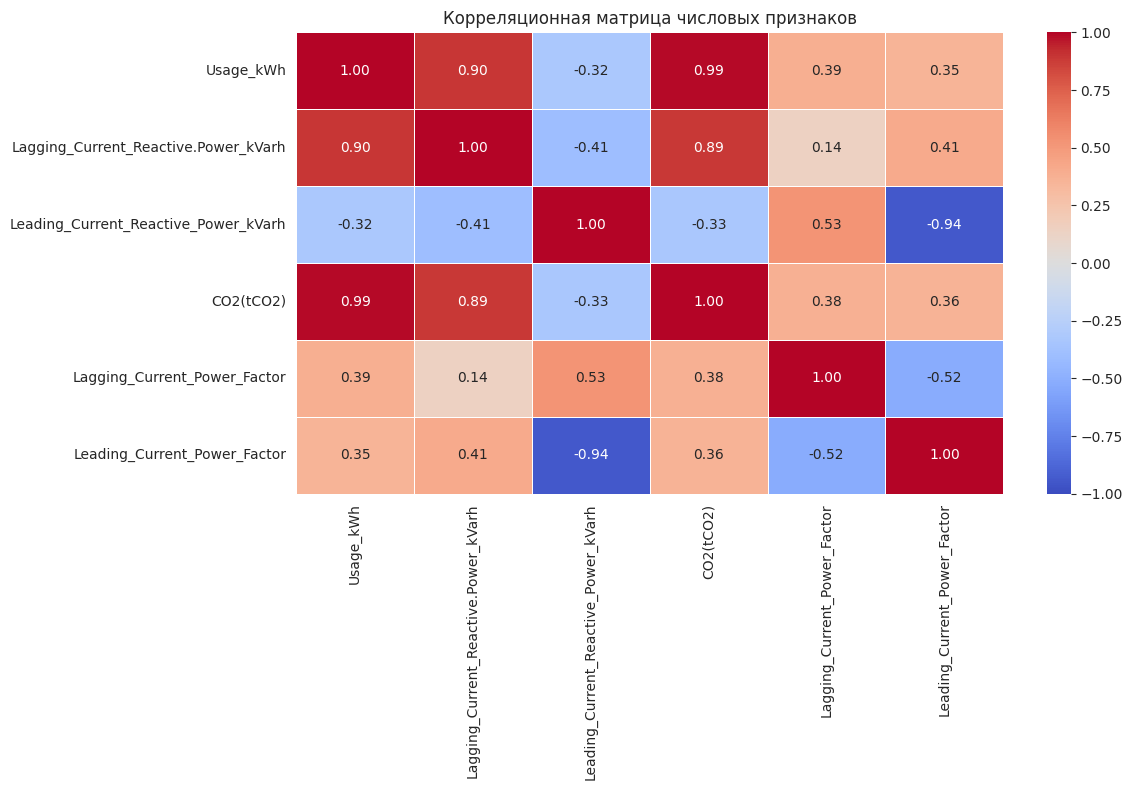

In [19]:
numeric_df = df.select_dtypes(include=['number']).drop(columns=['NSM'], errors='ignore')
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt='.2f',
    linewidths=0.5, center=0, vmin=-1, vmax=1
)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

In [20]:
corr_upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
strong_pair = corr_upper.reindex(corr_upper.abs().sort_values(ascending=False).index).head(5)

### Вывод по шагу 12 — некоторые числовые показатели меняются совместно

Самая сильная по модулю корреляция среди пар числовых переменных — между `Usage_kWh` и `CO2(tCO2)`: **r = +0,988**. Коэффициент Пирсона лежит в диапазоне от −1 до +1: знак показывает направление связи, а модуль — её силу.

**Как понимать +0,988:** в этом наборе большие значения CO₂ почти всегда сопровождаются большими значениями энергопотребления. Это очень сильная положительная линейная связь. Она не доказывает, что CO₂ вызывает потребление: оба показателя могут зависеть от общего режима нагрузки.

Диагональ корреляционной матрицы всегда равна 1, потому что переменная сравнивается сама с собой; матрица симметрична, поэтому коэффициенты над и под диагональю дублируют друг друга.

Сильная связь между признаками может означать избыточность информации и затруднять толкование отдельных коэффициентов линейной модели. Поэтому в следующем шаге отдельно сравниваем Пирсона и Спирмена и проверяем добавочную пользу CO₂ экспериментом.

## Шаг 13. Связи с Usage_kWh: Пирсон, Спирмен и показатель CO₂

Отдельно сравниваем корреляции с целевым `Usage_kWh`. Пирсон оценивает линейную связь и чувствителен к крупным значениям; Спирмен сравнивает ранги и лучше отражает монотонную, но не обязательно линейную зависимость. Разница между ними помогает не переинтерпретировать один коэффициент.

In [21]:
target_corr = corr_matrix['Usage_kWh'].drop('Usage_kWh').sort_values(ascending=False)
print('Корреляция числовых признаков с Usage_kWh:')
print(target_corr.to_string())
print(f"\nЧисло уникальных значений CO2(tCO2): {df['CO2(tCO2)'].nunique()}")
print('Уникальные значения CO2(tCO2):', sorted(df['CO2(tCO2)'].unique()))

Корреляция числовых признаков с Usage_kWh:
CO2(tCO2)                               0.988180
Lagging_Current_Reactive.Power_kVarh    0.896150
Lagging_Current_Power_Factor            0.385960
Leading_Current_Power_Factor            0.353566
Leading_Current_Reactive_Power_kVarh   -0.324922

Число уникальных значений CO2(tCO2): 8
Уникальные значения CO2(tCO2): [np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07)]


,Pearson,Spearman,Разница модулей
CO2(tCO2),0.988,0.882,0.107
Lagging_Current_Reactive.Power_kVarh,0.896,0.645,0.251
Lagging_Current_Power_Factor,0.386,0.375,0.011
Leading_Current_Power_Factor,0.354,0.194,0.160
Leading_Current_Reactive_Power_kVarh,-0.325,-0.132,0.193


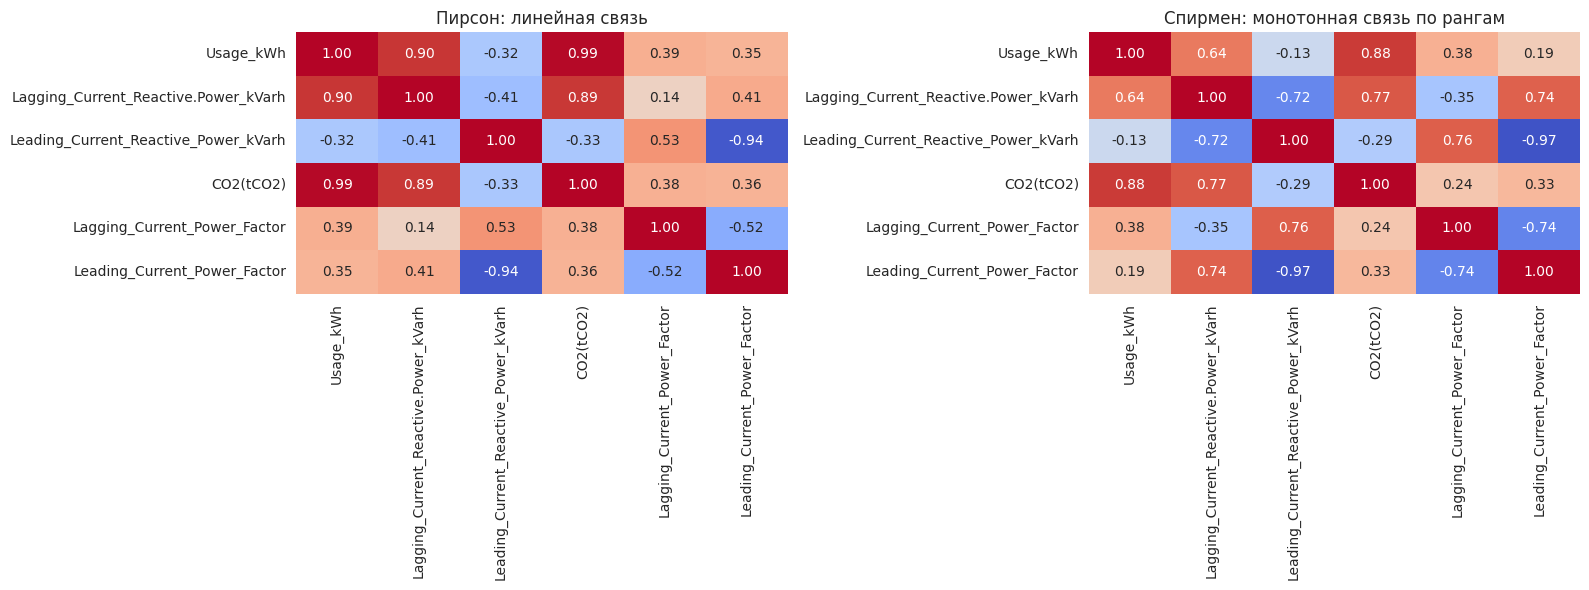

In [22]:
corr_spearman = numeric_df.corr(method='spearman')
corr_compare = pd.DataFrame({
    'Pearson': corr_matrix['Usage_kWh'].drop('Usage_kWh'),
    'Spearman': corr_spearman['Usage_kWh'].drop('Usage_kWh')
})
corr_compare['Разница модулей'] = (corr_compare['Pearson'].abs() - corr_compare['Spearman'].abs()).abs()
corr_compare = corr_compare.sort_values('Pearson', key=lambda s: s.abs(), ascending=False)
display(corr_compare.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', ax=axes[0], cbar=False)
axes[0].set_title('Пирсон: линейная связь')
sns.heatmap(corr_spearman, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', ax=axes[1], cbar=False)
axes[1].set_title('Спирмен: монотонная связь по рангам')
plt.tight_layout()
plt.show()

co2_pearson = float(corr_matrix.loc['CO2(tCO2)', 'Usage_kWh'])
co2_spearman = float(corr_spearman.loc['CO2(tCO2)', 'Usage_kWh'])
reactive_name = 'Lagging_Current_Reactive.Power_kVarh'
reactive_corr = float(corr_matrix.loc[reactive_name, 'Usage_kWh'])

In [23]:
top_corr = target_corr.head(5)

### Вывод по шагу 13 — связь CO₂ с потреблением сильная, но её нужно трактовать осторожно

| Связь с `Usage_kWh` | Пирсон | Спирмен | Как читать |
|---|---:|---:|---|
| `CO2(tCO2)` | **+0,988** | **+0,882** | Очень сильная положительная связь по обоим критериям |
| Отстающая реактивная энергия | **+0,896** | **+0,645** | Пирсон выше; крупные значения могут усиливать линейную связь |
| Отстающий Power Factor | +0,386 | +0,375 | Умеренная положительная связь |
| Опережающий Power Factor | +0,354 | +0,194 | Слабее выраженная ранговая связь |
| Опережающая реактивная энергия | −0,325 | −0,132 | Отрицательная связь умеренная/слабая по ранговой шкале |

**Пирсон** измеряет линейную связь между исходными значениями; **Спирмен** сравнивает ранги и отражает монотонную связь. Существенная разница между ними, например для отстающей реактивной энергии (0,896 против 0,645), говорит о том, что простой линейный коэффициент может сильнее зависеть от величины отдельных крупных наблюдений.

`CO2(tCO2)` имеет всего **8 уникальных уровней: от 0,00 до 0,07**. Это дискретный признак, поэтому высокий коэффициент может отражать ступенчатое изменение показателя вместе с общим режимом работы. В CSV нет описания алгоритма его расчёта.

Текущий CO₂ доступен в момент прогноза следующего интервала, поэтому он не является автоматически утечкой будущей цели. Но его полезность нужно проверить: сравнить одну и ту же модель на одном временном validation-отрезке с CO₂ и без него.

## Шаг 14. Сравнение распределений по Load_Type

Здесь недостаточно сказать, что категории разделяются. Смотрим количество наблюдений, среднее, медиану, стандартное отклонение и границы значений. Медиана описывает типичный интервал класса устойчивее к редким пикам, а перекрытие минимумов и максимумов показывает, можно ли определить категорию только одним порогом Usage_kWh.

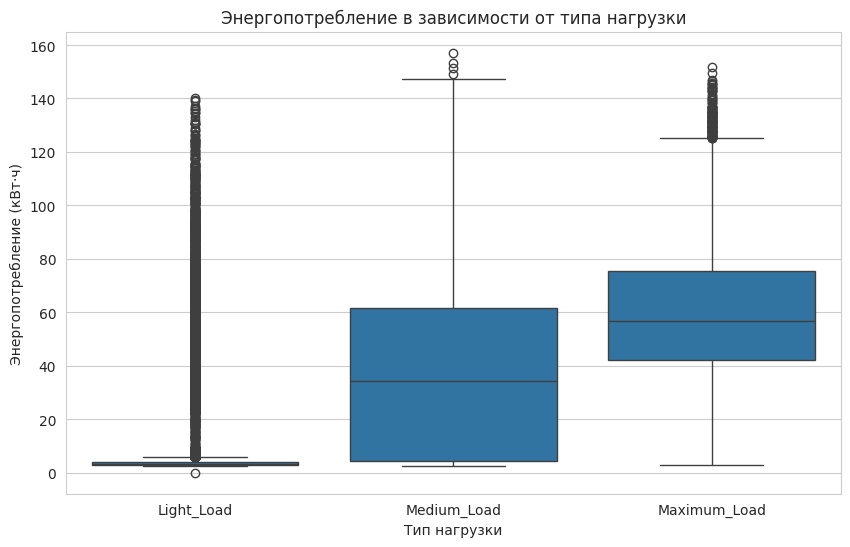

In [24]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Load_Type', y='Usage_kWh')
plt.title('Энергопотребление в зависимости от типа нагрузки')
plt.xlabel('Тип нагрузки')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.show()

In [25]:
load_summary = df.groupby('Load_Type')['Usage_kWh'].agg(
    Count='count', Mean='mean', Median='median', Std='std', Minimum='min', Maximum='max'
).sort_values('Median')
load_summary['Share_%'] = load_summary['Count'] / load_summary['Count'].sum() * 100
display(load_summary.round(2))

median_by_load = load_summary['Median']
range_labels = ', '.join([f"{name}: {row['Minimum']:.2f}–{row['Maximum']:.2f}" for name, row in load_summary.iterrows()])

,Count,Mean,Median,Std,Minimum,Maximum,Share_%
Load_Type,,,,,,,
Light_Load,18072,8.63,3.31,17.91,0.00,140.29,51.58
Medium_Load,9696,38.45,34.44,35.22,2.52,157.18,27.67
Maximum_Load,7272,59.27,56.63,29.75,2.92,151.67,20.75


In [26]:
ordered_load = load_summary.reindex(['Light_Load','Medium_Load','Maximum_Load'])

### Вывод по шагу 14 — `Load_Type` описывает разные режимы, но не задаёт жёсткие границы

| Категория | Наблюдений | Доля | Среднее, кВт·ч | Медиана, кВт·ч |
|---|---:|---:|---:|---:|
| `Light_Load` | 18 072 | 51,58% | **8,63** | **3,31** |
| `Medium_Load` | 9 696 | 27,67% | **38,45** | **34,44** |
| `Maximum_Load` | 7 272 | 20,75% | **59,27** | **56,63** |

Медиана `Maximum_Load` примерно в **17 раз** выше медианы `Light_Load` (56,63 против 3,31 кВт·ч). Значит, класс хорошо различает типичный уровень нагрузки. Средние также возрастают от Light к Maximum.

Но диапазоны сильно перекрываются: `Light_Load` достигает **140,29 кВт·ч**, `Medium_Load` начинается с **2,52**, а `Maximum_Load` — с **2,92 кВт·ч**. Следовательно, нельзя сказать, что каждому классу соответствует отдельный непересекающийся интервал `Usage_kWh`. Категория несёт дополнительный контекст о режиме, но не заменяет само измерение.

В модель включается только **текущая** категория `Load_Type`, доступная вместе с текущими измерениями. Будущий `Target_Load_Type` не передаём модели.

## Шаг 15. Различия между буднями, выходными и днями недели

Сравниваем среднее и медиану потребления по дням и по группам Weekday/Weekend. Если обе меры ниже в выходные, различие не объясняется только несколькими высокими интервалами в будни. При этом среднее и медиана могут отличаться из-за пиков.

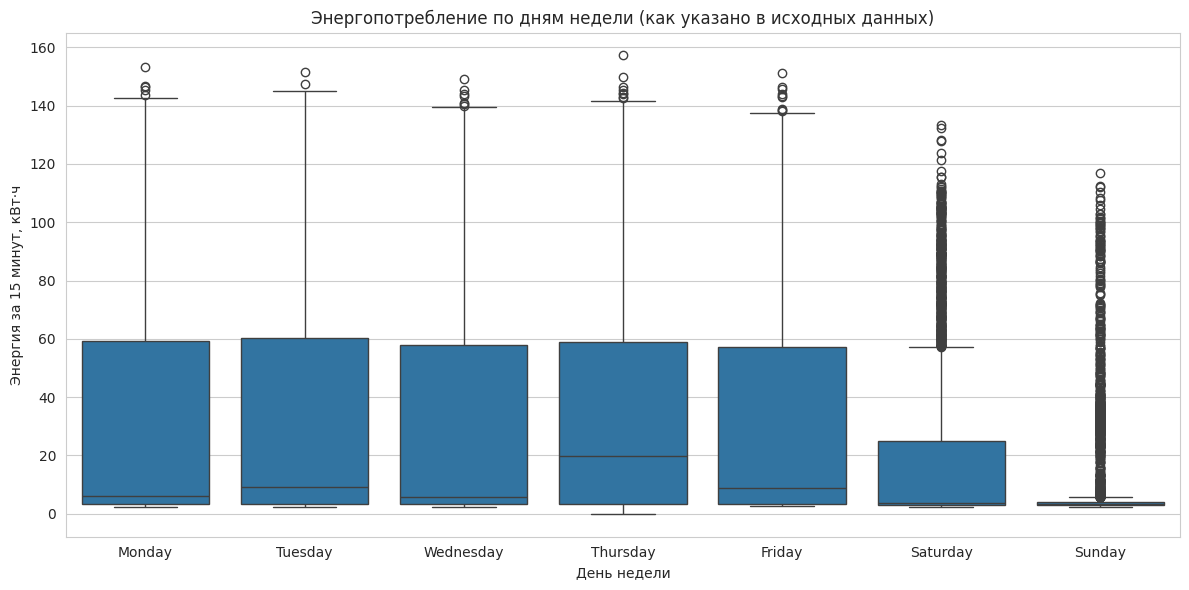

In [27]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df, x='Day_of_week', y='Usage_kWh',
    order=day_order
)
plt.title('Энергопотребление по дням недели (как указано в исходных данных)')
plt.xlabel('День недели')
plt.ylabel('Энергия за 15 минут, кВт·ч')
plt.tight_layout()
plt.show()

In [28]:
weekday_summary = df.groupby('Day_of_week')['Usage_kWh'].agg(['count', 'mean', 'median']).reindex(day_order)
weekday_summary.index.name = 'День недели'
display(weekday_summary.round(2))
weekend_summary = df.groupby('WeekStatus')['Usage_kWh'].agg(['mean', 'median', 'count'])
display(weekend_summary.round(2))
if {'Weekday', 'Weekend'}.issubset(weekend_summary.index):
    mean_reduction = (1 - weekend_summary.loc['Weekend', 'mean'] / weekend_summary.loc['Weekday', 'mean']) * 100
    median_reduction = (1 - weekend_summary.loc['Weekend', 'median'] / weekend_summary.loc['Weekday', 'median']) * 100
else:
    mean_reduction = median_reduction = np.nan

,count,mean,median
День недели,,,
Monday,5087,33.09,6.19
Tuesday,4993,34.42,9.11
Wednesday,4992,32.28,5.87
Thursday,4992,35.09,19.85
Friday,4992,33.19,9.00
Saturday,4992,15.97,3.74
Sunday,4992,7.57,3.20


,mean,median,count
WeekStatus,,,
Weekday,33.61,7.56,25056
Weekend,11.77,3.46,9984


### Вывод по шагу 15 — календарь связан с уровнем нагрузки

| Период | Среднее, кВт·ч за 15 минут | Медиана, кВт·ч |
|---|---:|---:|
| Будни | **33,61** | **7,56** |
| Выходные | **11,77** | **3,46** |

Среднее потребление в выходные ниже примерно на **65,0%**, медиана — на **54,2%**. Поскольку обе характеристики снижаются в одном направлении, различие не объясняется только несколькими большими пиками в будни: типичный интервал тоже ниже.

По дням недели наибольшее среднее наблюдается в четверг (**35,09 кВт·ч**), наименьшее — в воскресенье (**7,57 кВт·ч**). Среднее учитывает крупные значения, а медиана показывает центральный интервал; их расхождение объясняется неоднородностью нагрузки.

**Что это значит для модели:** день недели и признак выходного могут помогать прогнозу, потому что режим энергопотребления связан с календарём. Ограничение — анализ охватывает один год и один завод; проценты нельзя автоматически переносить на другой год или предприятие.

## Шаг 16. Профиль нагрузки по часам и дням недели

Средний профиль по часам показывает типичный суточный цикл, а тепловая карта «день недели × час» позволяет найти сочетания, где среднее потребление особенно высоко или низко. Для каждого часа показывается среднее значение за 15-минутный интервал, а не сумма за час.

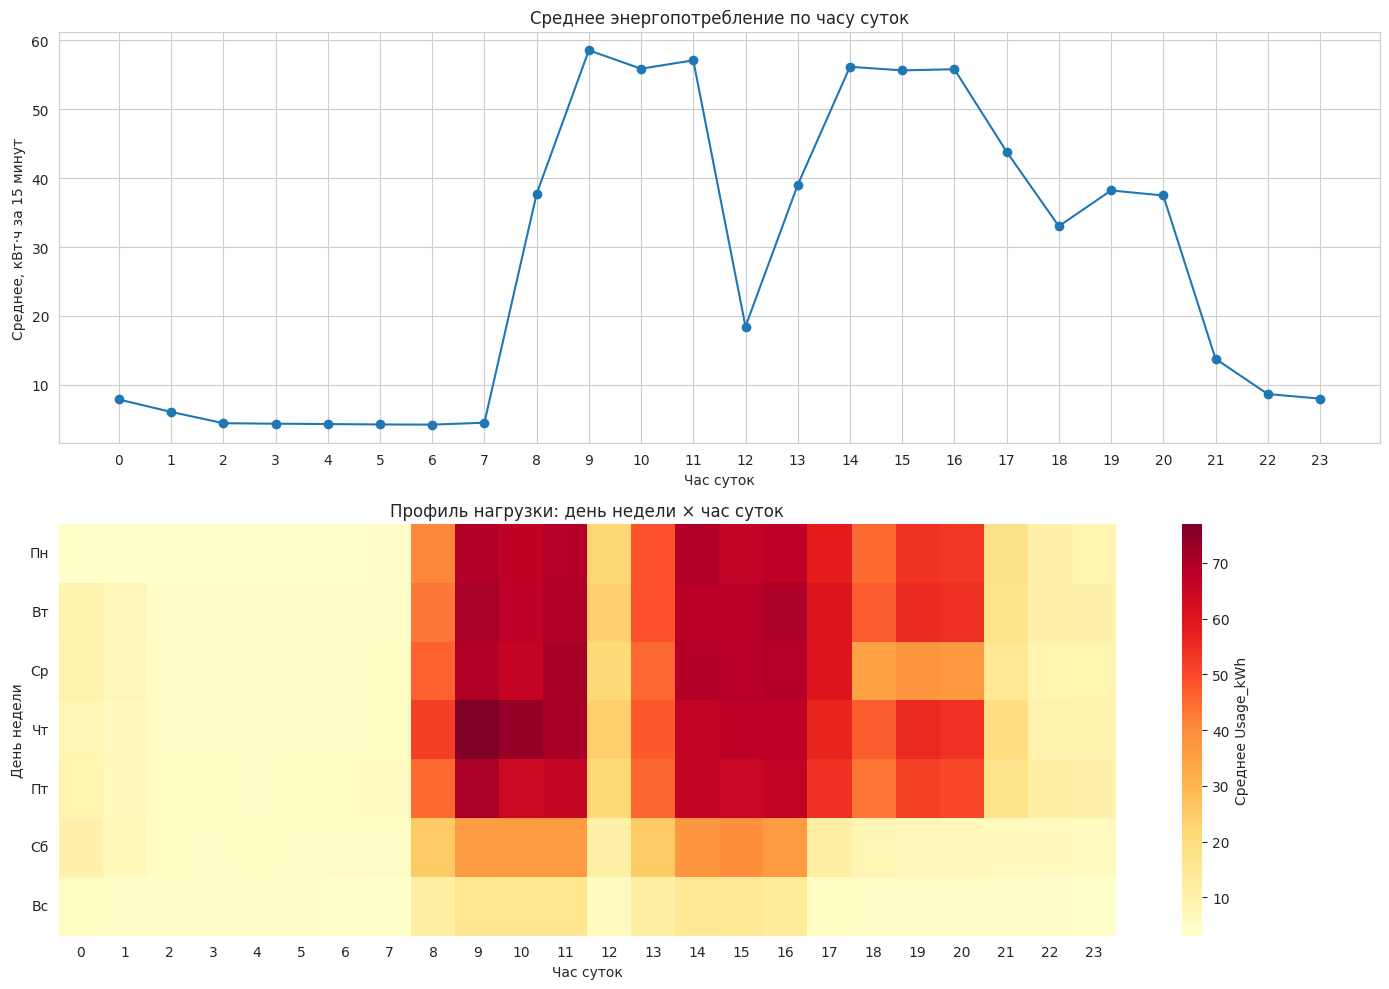

In [29]:
df['hour_of_day'] = df['date'].dt.hour
df['weekday_from_timestamp'] = df['date'].dt.dayofweek

hourly_profile = df.groupby('hour_of_day')['Usage_kWh'].mean()
weekly_hour_profile = df.pivot_table(
    index='weekday_from_timestamp',
    columns='hour_of_day',
    values='Usage_kWh',
    aggfunc='mean'
).reindex(range(7))

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
axes[0].plot(hourly_profile.index, hourly_profile.values, marker='o')
axes[0].set_xticks(range(24))
axes[0].set_title('Среднее энергопотребление по часу суток')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Среднее, кВт·ч за 15 минут')

sns.heatmap(
    weekly_hour_profile,
    cmap='YlOrRd',
    ax=axes[1],
    cbar_kws={'label': 'Среднее Usage_kWh'}
)
axes[1].set_yticks(
    np.arange(7) + 0.5,
    ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'],
    rotation=0
)
axes[1].set_title('Профиль нагрузки: день недели × час суток')
axes[1].set_xlabel('Час суток')
axes[1].set_ylabel('День недели')
plt.tight_layout()
plt.show()

In [30]:
peak_hour = int(hourly_profile.idxmax())
low_hour = int(hourly_profile.idxmin())

In [31]:
max_cell = weekly_hour_profile.stack().idxmax(); min_cell = weekly_hour_profile.stack().idxmin()
dow_ru = ['понедельник','вторник','среду','четверг','пятницу','субботу','воскресенье']

### Вывод по шагу 16 — характерный максимум приходится на утренние часы, но зависит от дня недели

Среднее потребление за 15-минутный интервал наиболее высоко в **09:00 — 58,55 кВт·ч**, а минимально в **06:00 — 4,22 кВт·ч**. Разница между средними составляет **54,33 кВт·ч за интервал**.

Тепловая карта уточняет картину: максимальное сочетание — **четверг, 09:00: 76,95 кВт·ч**; минимальное — **понедельник, 06:00: 3,15 кВт·ч**. Значение в ячейке — среднее всех наблюдений соответствующего часа и дня недели, а не отдельный пик и не сумма за полный час.

**Интерпретация:** на энергопотребление влияет не только время суток, но и день недели. Поэтому модель получает оба вида календарной информации. При этом графики показывают усреднённый профиль: конкретный день может отличаться от него, а сама визуализация не устанавливает технологическую причину утреннего подъёма.

## Шаг 17. Автокорреляция и обоснование временных лагов

Автокорреляция сравнивает ряд с его копией, сдвинутой в прошлое на заданное число строк. При шаге 15 минут лаг 1 равен 15 минутам, 4 — часу, 96 — суткам, 672 — неделе. Значение +1 означает сильное совпадение линейной динамики, 0 — отсутствие линейной связи на этом лаге, −1 — противоположное движение.

,"Лаг, наблюдений",Интервал,Автокорреляция
0,1,15 минут,0.913
1,4,1 час,0.688
2,96,24 часа,0.606
3,672,7 суток,0.677


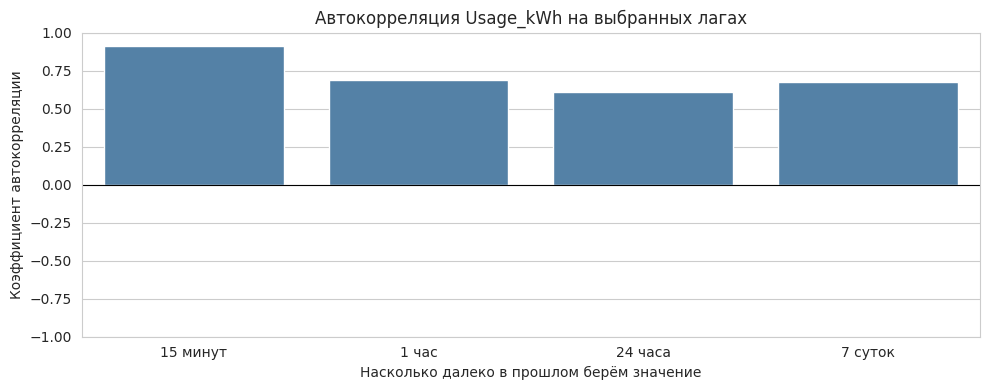

In [32]:
lags_to_check = {1: '15 минут', 4: '1 час', 96: '24 часа', 672: '7 суток'}
acf_values = pd.Series({
    label: df['Usage_kWh'].autocorr(lag=lag)
    for lag, label in lags_to_check.items()
}, name='Автокорреляция')
acf_table = pd.DataFrame({
    'Лаг, наблюдений': list(lags_to_check.keys()),
    'Интервал': list(lags_to_check.values()),
    'Автокорреляция': acf_values.values
})
display(acf_table.round(3))

plt.figure(figsize=(10, 4))
sns.barplot(data=acf_table, x='Интервал', y='Автокорреляция', color='steelblue')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylim(-1, 1)
plt.title('Автокорреляция Usage_kWh на выбранных лагах')
plt.xlabel('Насколько далеко в прошлом берём значение')
plt.ylabel('Коэффициент автокорреляции')
plt.tight_layout()
plt.show()

strongest_lag = acf_table.iloc[acf_table['Автокорреляция'].abs().argmax()]

In [33]:
acf_by_lag = dict(zip(acf_table['Интервал'], acf_table['Автокорреляция']))

### Вывод по шагу 17 — ряд обладает выраженной временной инерцией

| Сдвиг | Автокорреляция | Интерпретация |
|---|---:|---|
| 15 минут | **+0,913** | Очень сильная связь соседних интервалов |
| 1 час | **+0,688** | Заметная положительная связь через час |
| 24 часа | **+0,606** | Потребление связано с уровнем в то же время предыдущих суток |
| 7 суток | **+0,677** | Выраженная повторяемость на недельном расстоянии |

Автокорреляция сравнивает временной ряд с ним же, сдвинутым на заданное количество интервалов. Значение +0,913 на 15 минутах говорит, что соседние наблюдения часто движутся согласованно: текущее потребление содержит информацию о ближайшем будущем.

Недельная автокорреляция (+0,677) в этой проверке выше суточной (+0,606). Это согласуется с возможной ролью повторяющегося недельного календарного режима, но не означает, что каждая неделя идентична предыдущей.

**Решение для Feature Engineering:** включить историю за час, сутки и неделю. Автокорреляция формирует обоснованную гипотезу, но окончательная полезность лагов определяется только качеством прогноза на более поздних временных отрезках.

## Шаг 18. План Feature Engineering: что доступно в момент прогноза

Прогноз строится на следующий 15-минутный интервал. В момент времени t нам доступны измерения за текущий интервал и все предыдущие значения. Будущие календарные параметры (например, час и день недели следующего интервала) известны заранее. Будущее потребление и будущую категорию нагрузки использовать нельзя: это утечка целевой информации.

In [34]:
md_feature_plan = pd.DataFrame([
    ('Текущие измерения', 'Потребление, реактивная энергия, power factor, CO₂', 'доступны в момент t'),
    ('Календарь прогноза', 'час, минута, день недели, месяц следующего интервала', 'известен заранее'),
    ('Циклические признаки', 'sin/cos для времени суток и дня недели', 'известны заранее'),
    ('История', 'лаг 1 час, 24 часа, 7 суток; rolling mean/std за час', 'рассчитываются только по прошлым и текущим данным'),
    ('Цель', 'Usage_kWh следующего интервала', 'используется только как y, не как X')
], columns=['Группа', 'Примеры', 'Доступность'])
display(md_feature_plan)

,Группа,Примеры,Доступность
0,Текущие измерения,"Потребление, реактивная энергия, power factor,...",доступны в момент t
1,Календарь прогноза,"час, минута, день недели, месяц следующего инт...",известен заранее
2,Циклические признаки,sin/cos для времени суток и дня недели,известны заранее
3,История,"лаг 1 час, 24 часа, 7 суток; rolling mean/std ...",рассчитываются только по прошлым и текущим данным
4,Цель,Usage_kWh следующего интервала,"используется только как y, не как X"


### Зафиксированная логика построения признаков

Задача формулируется как прогноз на один шаг вперёд: на момент **t** известны измерения и история до текущего интервала, а требуется оценить `Usage_kWh` в момент **t + 15 минут**.

| Информация | Можно ли использовать при прогнозе? | Почему |
|---|---|---|
| Текущие электрические измерения | **Да** | Они уже получены в момент t |
| История потребления | **Да** | Это прошлые и текущие наблюдения |
| Час и день недели следующего интервала | **Да** | Календарное время известно заранее |
| Будущий `Usage_kWh` | **Нет** | Это и есть целевая переменная |
| Будущий `Load_Type` | **Нет** | Будущая категория неизвестна в момент прогноза |

Это правило определяет все следующие шаги. Признак должен быть не просто связан с целью, а реально доступен в тот момент, когда система должна сделать прогноз. Иначе возникает *data leakage* — модель получает информацию, которой в реальном применении у неё не будет.

## Шаг 19. Формирование целевой переменной на следующий интервал

Сдвигаем `Usage_kWh` на одну строку вверх по времени: значение в следующей строке становится целевым. Также сохраняем временную отметку будущего интервала и будущую категорию только для последующей диагностики. Эти две колонки не будут входить в `X`.

In [35]:
df = df.copy()
df['Target_Next_15min'] = df['Usage_kWh'].shift(-1)
df['Target_Date'] = df['date'].shift(-1)
df['Target_Load_Type'] = df['Load_Type'].shift(-1)  # диагностика, не признак

display(df[['date', 'Usage_kWh', 'Target_Date', 'Target_Next_15min', 'Load_Type', 'Target_Load_Type']].head(8))
assert (df['Target_Date'].dropna() - df['date'].dropna().iloc[:len(df)-1]).eq(pd.Timedelta(minutes=15)).all()
print('Проверка сдвига цели пройдена: target_date отличается от текущего времени на 15 минут.')

,date,Usage_kWh,Target_Date,Target_Next_15min,Load_Type,Target_Load_Type
0,2018-01-01 00:15:00,3.17,2018-01-01 00:30:00,4.00,Light_Load,Light_Load
1,2018-01-01 00:30:00,4.00,2018-01-01 00:45:00,3.24,Light_Load,Light_Load
2,2018-01-01 00:45:00,3.24,2018-01-01 01:00:00,3.31,Light_Load,Light_Load
3,2018-01-01 01:00:00,3.31,2018-01-01 01:15:00,3.82,Light_Load,Light_Load
4,2018-01-01 01:15:00,3.82,2018-01-01 01:30:00,3.28,Light_Load,Light_Load
5,2018-01-01 01:30:00,3.28,2018-01-01 01:45:00,3.60,Light_Load,Light_Load
6,2018-01-01 01:45:00,3.60,2018-01-01 02:00:00,3.60,Light_Load,Light_Load
7,2018-01-01 02:00:00,3.60,2018-01-01 02:15:00,3.28,Light_Load,Light_Load


Проверка сдвига цели пройдена: target_date отличается от текущего времени на 15 минут.


### Результат шага 19 — цель сдвинута на один интервал вперёд

Получено **35 039 строк** с известным следующим наблюдением. Последняя строка исходного ряда не имеет целевого значения: после неё в CSV нет ещё одного измерения.

Например, строка с текущим временем **10:00** содержит измерения, доступные в момент t, а `Target_Next_15min` соответствует энергопотреблению в **10:15**. Таким образом, модель учится именно прогнозировать следующий 15-минутный интервал, а не воспроизводить текущий.

`Target_Date` и `Target_Load_Type` сохраняются только для последующего анализа ошибок по времени и категории. Они не входят в матрицу признаков `X`.

## Шаг 20. Календарные признаки прогнозируемого интервала

Создаём признаки именно для `Target_Date`, то есть будущего интервала, а не для текущего измерения. Кодируем время суток и день недели через синус и косинус: это позволяет модели видеть близость 23:45 и 00:00, а также воскресенья и понедельника на циклической шкале.

In [36]:
forecast_time = pd.to_datetime(df['Target_Date'])
df['forecast_hour'] = forecast_time.dt.hour
df['forecast_minute'] = forecast_time.dt.minute
df['forecast_month'] = forecast_time.dt.month
df['forecast_day_of_year'] = forecast_time.dt.dayofyear
df['forecast_weekday'] = forecast_time.dt.dayofweek
df['forecast_is_weekend'] = (df['forecast_weekday'] >= 5).astype(float)
df['forecast_NSM'] = df['forecast_hour'] * 3600 + df['forecast_minute'] * 60

df['forecast_time_sin'] = np.sin(2*np.pi*df['forecast_NSM']/86400)
df['forecast_time_cos'] = np.cos(2*np.pi*df['forecast_NSM']/86400)
df['forecast_dow_sin'] = np.sin(2*np.pi*df['forecast_weekday']/7)
df['forecast_dow_cos'] = np.cos(2*np.pi*df['forecast_weekday']/7)

display(df[['date','Target_Date','forecast_hour','forecast_minute','forecast_weekday','forecast_is_weekend','forecast_time_sin','forecast_time_cos']].head(10))

,date,Target_Date,forecast_hour,forecast_minute,forecast_weekday,forecast_is_weekend,forecast_time_sin,forecast_time_cos
0,2018-01-01 00:15:00,2018-01-01 00:30:00,0.0,30.0,0.0,0.0,0.130526,0.991445
1,2018-01-01 00:30:00,2018-01-01 00:45:00,0.0,45.0,0.0,0.0,0.195090,0.980785
2,2018-01-01 00:45:00,2018-01-01 01:00:00,1.0,0.0,0.0,0.0,0.258819,0.965926
3,2018-01-01 01:00:00,2018-01-01 01:15:00,1.0,15.0,0.0,0.0,0.321439,0.946930
4,2018-01-01 01:15:00,2018-01-01 01:30:00,1.0,30.0,0.0,0.0,0.382683,0.923880
5,2018-01-01 01:30:00,2018-01-01 01:45:00,1.0,45.0,0.0,0.0,0.442289,0.896873
6,2018-01-01 01:45:00,2018-01-01 02:00:00,2.0,0.0,0.0,0.0,0.500000,0.866025
7,2018-01-01 02:00:00,2018-01-01 02:15:00,2.0,15.0,0.0,0.0,0.555570,0.831470
8,2018-01-01 02:15:00,2018-01-01 02:30:00,2.0,30.0,0.0,0.0,0.608761,0.793353
9,2018-01-01 02:30:00,2018-01-01 02:45:00,2.0,45.0,0.0,0.0,0.659346,0.751840


### Вывод по шагу 20 — календарные признаки рассчитаны для прогнозируемого интервала

Час, минута, день недели и признак выходного вычисляются по `Target_Date`, то есть по времени **следующего** измерения. Это корректно: будущая календарная дата известна заранее, даже если будущее потребление ещё неизвестно.

Время суток и день недели дополнительно кодируются через синус и косинус. Такой способ учитывает цикличность: 23:45 и 00:00 соседствуют во времени, хотя числовые значения часа равны 23 и 0. Аналогично воскресенье и понедельник соседствуют в недельном цикле.

На будущий интервал выходного приходится **28,5%** строк. Этот признак помогает модели различать календарные режимы. Он не раскрывает будущее энергопотребление и поэтому допустим для прогноза.

## Шаг 21. Лаговые и скользящие признаки потребления

Формируем историю: значение час назад, сутки назад и неделю назад; среднее и стандартное отклонение четырёх последних 15-минутных наблюдений. Скользящее среднее описывает текущий уровень за последний час, стандартное отклонение — насколько резко менялось потребление внутри этого часа.

In [37]:
df['rolling_mean_1h'] = df['Usage_kWh'].rolling(window=4, min_periods=4).mean()
df['rolling_std_1h'] = df['Usage_kWh'].rolling(window=4, min_periods=4).std()
df['lag_1h'] = df['Usage_kWh'].shift(4)
df['lag_24h'] = df['Usage_kWh'].shift(96)
df['lag_7d'] = df['Usage_kWh'].shift(672)

lag_columns = ['lag_1h','lag_24h','lag_7d','rolling_mean_1h','rolling_std_1h']
display(df[['date','Usage_kWh'] + lag_columns].iloc[670:678])

,date,Usage_kWh,lag_1h,lag_24h,lag_7d,rolling_mean_1h,rolling_std_1h
670,2018-01-07 23:45:00,3.42,3.60,3.31,NaN,3.4850,0.193477
671,2018-01-08 00:00:00,3.28,3.64,3.60,NaN,3.3950,0.180647
672,2018-01-08 00:15:00,3.78,3.24,3.13,3.17,3.5300,0.223010
673,2018-01-08 00:30:00,3.38,3.64,3.49,4.00,3.4650,0.218098
674,2018-01-08 00:45:00,3.31,3.42,3.64,3.24,3.4375,0.232146
675,2018-01-08 01:00:00,3.89,3.28,3.20,3.31,3.5900,0.287866
676,2018-01-08 01:15:00,3.35,3.78,3.56,3.82,3.4825,0.273176
677,2018-01-08 01:30:00,3.31,3.38,3.49,3.28,3.4650,0.283960


### Вывод по шагу 21 — созданы признаки краткосрочной и повторяющейся истории

При шаге наблюдений 15 минут:

| Признак | Сдвиг / окно | Что он описывает |
|---|---:|---|
| `lag_1h` | 4 строки | Энергию за 15 минут в момент час назад |
| `lag_24h` | 96 строк | Значение в то же время предыдущих суток |
| `lag_7d` | 672 строки | Значение в тот же момент неделю назад |
| `rolling_mean_1h` | 4 последних значения | Средний уровень потребления за последний час |
| `rolling_std_1h` | 4 последних значения | Изменчивость потребления в последнем часе |

Высокое `rolling_mean_1h` означает, что нагрузка была повышенной не только в одном интервале, но и в среднем за последний час. Высокое `rolling_std_1h` означает, что внутри этого часа потребление заметно колебалось; низкое — что оно было относительно ровным.

Все эти признаки строятся только по текущим и прошлым измерениям. Первые 672 строки не имеют полной недельной истории, поэтому `lag_7d` для них будет пустым — это техническое ограничение, а не ошибка исходного измерения.

## Шаг 22. Формирование полной обучаемой таблицы

Удаляем только строки, для которых нельзя получить все необходимые лаги/скользящие показатели или целевое значение следующего интервала. Это не фильтрация экстремумов и не удаление «плохого» потребления.

In [38]:
# Удаляем только начало ряда без 7-дневной истории и последнюю строку без целевого значения.
rows_before_features_filter = len(df)
df = df.dropna(subset=[
    'Target_Next_15min', 'Target_Date',
    'rolling_mean_1h', 'rolling_std_1h', 'lag_1h', 'lag_24h', 'lag_7d'
]).reset_index(drop=True)

print('Количество строк после подготовки признаков:', len(df))
display(df[[
    'date', 'Usage_kWh', 'lag_1h', 'lag_24h', 'lag_7d', 'rolling_mean_1h',
    'Target_Date', 'Target_Next_15min', 'forecast_hour'
]].head(10))
print('Удалено строк из-за недоступной истории/целевого значения:', rows_before_features_filter - len(df))

Количество строк после подготовки признаков: 34367


,date,Usage_kWh,lag_1h,lag_24h,lag_7d,rolling_mean_1h,Target_Date,Target_Next_15min,forecast_hour
0,2018-01-08 00:15:00,3.78,3.24,3.13,3.17,3.5300,2018-01-08 00:30:00,3.38,0.0
1,2018-01-08 00:30:00,3.38,3.64,3.49,4.00,3.4650,2018-01-08 00:45:00,3.31,0.0
2,2018-01-08 00:45:00,3.31,3.42,3.64,3.24,3.4375,2018-01-08 01:00:00,3.89,1.0
3,2018-01-08 01:00:00,3.89,3.28,3.20,3.31,3.5900,2018-01-08 01:15:00,3.35,1.0
4,2018-01-08 01:15:00,3.35,3.78,3.56,3.82,3.4825,2018-01-08 01:30:00,3.31,1.0
5,2018-01-08 01:30:00,3.31,3.38,3.49,3.28,3.4650,2018-01-08 01:45:00,4.00,1.0
6,2018-01-08 01:45:00,4.00,3.31,3.31,3.60,3.6375,2018-01-08 02:00:00,3.31,2.0
7,2018-01-08 02:00:00,3.31,3.89,3.74,3.60,3.4925,2018-01-08 02:15:00,3.42,2.0
8,2018-01-08 02:15:00,3.42,3.35,3.38,3.28,3.5100,2018-01-08 02:30:00,3.89,2.0
9,2018-01-08 02:30:00,3.89,3.31,3.17,3.78,3.6550,2018-01-08 02:45:00,3.38,2.0


Удалено строк из-за недоступной истории/целевого значения: 673


### Вывод по шагу 22 — обучаемая таблица уменьшилась только из-за недоступной истории

| Состояние | Число строк |
|---|---:|
| До технической фильтрации | **35 040** |
| После фильтрации | **34 367** |
| Исключено | **673** |

Из 673 исключённых строк **672** относятся к началу ряда, где невозможно рассчитать недельный лаг `lag_7d`. Ещё одна — последняя строка, для которой отсутствует потребление следующего интервала и, следовательно, целевая переменная.

**Важно:** фильтрация не удаляла наблюдения из-за высокого или низкого энергопотребления. Статистические пики остаются в данных. После очистки технических пропусков целевая переменная и необходимые признаки заполнены.

## Шаг 23. Проверка связи новых признаков с целевым значением

Смотрим, как созданные временные признаки коррелируют с `Target_Next_15min`. Это первичная проверка информативности: сильная корреляция может быть полезным сигналом, но слабая линейная связь не исключает нелинейной ценности для деревьев.

rolling_mean_1h        0.844028
lag_7d                 0.645461
lag_1h                 0.638670
lag_24h                0.576774
rolling_std_1h         0.546589
forecast_dow_sin       0.225598
forecast_dow_cos      -0.071258
forecast_is_weekend   -0.293319
forecast_time_sin     -0.306556
forecast_time_cos     -0.451140
Name: Target_Next_15min, dtype: float64


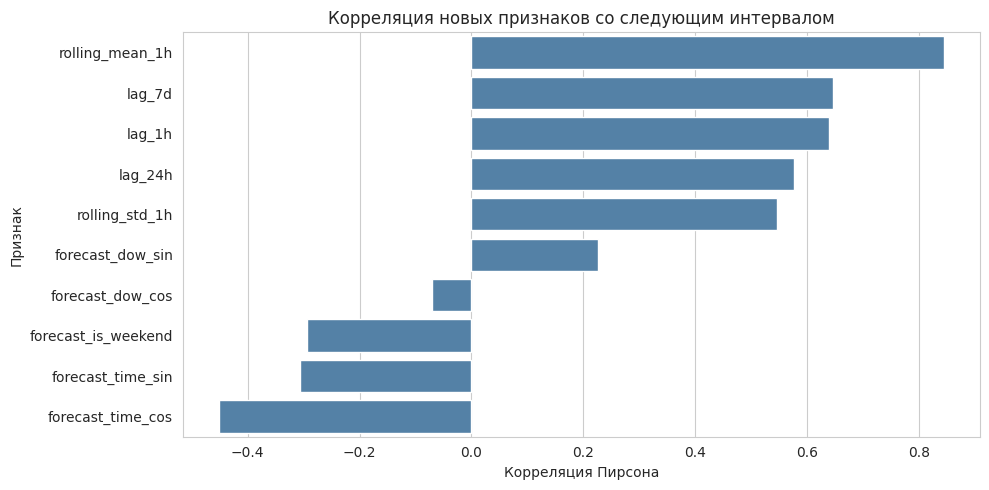

In [39]:
new_features = [
    'forecast_time_sin', 'forecast_time_cos',
    'forecast_dow_sin', 'forecast_dow_cos', 'forecast_is_weekend',
    'rolling_mean_1h', 'rolling_std_1h', 'lag_1h', 'lag_24h', 'lag_7d'
]

new_corr = df[new_features + ['Target_Next_15min']].corr()['Target_Next_15min']
new_corr = new_corr.drop('Target_Next_15min').sort_values(ascending=False)

print(new_corr)

plt.figure(figsize=(10, 5))
sns.barplot(x=new_corr.values, y=new_corr.index, color='steelblue')
plt.title('Корреляция новых признаков со следующим интервалом')
plt.xlabel('Корреляция Пирсона')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

### Вывод по шагу 23 — среди новых признаков выделяется среднее за последний час

Наибольшая положительная корреляция с `Target_Next_15min` наблюдается у `rolling_mean_1h`: **+0,844**. Это означает, что высокий средний уровень потребления за последний час обычно сопровождается высоким потреблением в следующем интервале.

Наиболее отрицательная связь среди показанных новых признаков — у `forecast_time_cos`: **−0,451**. Это отражает связь фазы суточного цикла с уровнем потребления; знак «минус» не означает, что признак физически уменьшает энергопотребление.

Корреляция Пирсона оценивает линейную связь каждого признака с целью по отдельности. Она не учитывает все взаимодействия признаков и не измеряет вклад в готовую модель. Поэтому по этим коэффициентам нельзя окончательно ранжировать признаки — это проверяется сравнением моделей и важностью признаков.

## Шаг 24. Формирование списка признаков и разделение X / y

Собираем признаки, которые доступны в момент формирования прогноза. В `X` входят текущие электрические измерения, календарь будущего интервала и история потребления. В `y` — только `Target_Next_15min`. Временная метка следующего интервала и следующая категория намеренно исключены.

In [40]:
target = 'Target_Next_15min'
features = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type',
    'forecast_hour', 'forecast_minute', 'forecast_month',
    'forecast_day_of_year', 'forecast_weekday', 'forecast_is_weekend',
    'forecast_NSM', 'forecast_time_sin', 'forecast_time_cos',
    'forecast_dow_sin', 'forecast_dow_cos',
    'rolling_mean_1h', 'rolling_std_1h', 'lag_1h', 'lag_24h', 'lag_7d'
]
X = df[features].copy()
y = df[target].copy()
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object','category']).columns.tolist()

feature_groups = pd.DataFrame([
    ('Текущие измерения', 7, 'активная/реактивная энергия, CO₂, power factor, NSM'),
    ('Текущие категории', 3, 'WeekStatus, Day_of_week, Load_Type'),
    ('Календарь будущего интервала', 11, 'час, день недели, циклические и календарные признаки'),
    ('История потребления', 5, 'лаги и скользящие статистики')
], columns=['Группа признаков','Заявлено полей','Содержание'])
display(feature_groups)
print('Всего признаков:', len(features), '| Числовых:', len(numeric_features), '| Категориальных:', len(categorical_features))
assert target not in features
assert not {'Target_Date','Target_Load_Type','Target_Next_15min'}.intersection(features)

,Группа признаков,Заявлено полей,Содержание
0,Текущие измерения,7,"активная/реактивная энергия, CO₂, power factor..."
1,Текущие категории,3,"WeekStatus, Day_of_week, Load_Type"
2,Календарь будущего интервала,11,"час, день недели, циклические и календарные пр..."
3,История потребления,5,лаги и скользящие статистики


Всего признаков: 26 | Числовых: 23 | Категориальных: 3


### Вывод по шагу 24 — сформирована матрица из 26 признаков

| Группа признаков | Количество | Содержание |
|---|---:|---|
| Текущие измерения | **7** | Активная/реактивная энергия, CO₂, коэффициенты мощности и `NSM` |
| Текущие категории | **3** | `WeekStatus`, `Day_of_week`, `Load_Type` |
| Календарь будущего интервала | **11** | Час, день недели, месяц и циклические/календарные признаки |
| История потребления | **5** | Три лага и две скользящие статистики |
| **Всего** | **26** | 23 числовых и 3 категориальных признака |

Текущий `Usage_kWh` допустим как вход: в момент прогноза он уже измерен. `Target_Next_15min` — это ответ модели, поэтому в `X` его быть не должно. Аналогично исключены `Target_Date` и будущий `Target_Load_Type`: первая нужна для временного анализа результата, вторая — для диагностики по классу, но обе недоступны как входные признаки в данной постановке.

## Шаг 25. Контроль готовности признаков и утечек данных

Проверяем пропуски, порядок временных отметок и корректность интервалов уже в обучаемой таблице. Отдельно выводим будущие поля, которые запрещено передавать модели. Это повторная страховка после Feature Engineering.

In [41]:
check_columns = ['lag_1h','lag_24h','lag_7d','rolling_mean_1h','rolling_std_1h',
                 'forecast_time_sin','forecast_time_cos','forecast_dow_sin','forecast_dow_cos']
feature_check = pd.DataFrame({
    'Признак': check_columns,
    'Пропуски': [int(df[c].isna().sum()) for c in check_columns],
    'Уникальных значений': [int(df[c].nunique()) for c in check_columns]
})
display(feature_check)
print('Пропусков в X:', int(X.isna().sum().sum()))
print('Пропусков в y:', int(y.isna().sum()))
print('Строго возрастающее время:', bool(df['date'].is_monotonic_increasing))
print('Будущие поля в X:', sorted({'Target_Date','Target_Load_Type','Target_Next_15min'}.intersection(X.columns)))
assert X.isna().sum().sum() == 0 and y.isna().sum() == 0
assert df['date'].is_monotonic_increasing
assert df['date'].diff().dropna().eq(pd.Timedelta(minutes=15)).all()
assert not {'Target_Date','Target_Load_Type','Target_Next_15min'}.intersection(X.columns)

,Признак,Пропуски,Уникальных значений
0,lag_1h,0,3309
1,lag_24h,0,3309
2,lag_7d,0,3341
3,rolling_mean_1h,0,23893
4,rolling_std_1h,0,32040
5,forecast_time_sin,0,84
6,forecast_time_cos,0,89
7,forecast_dow_sin,0,7
8,forecast_dow_cos,0,7


Пропусков в X: 0
Пропусков в y: 0
Строго возрастающее время: True
Будущие поля в X: []


### Вывод по шагу 25 — матрица признаков готова к обучению

| Контроль | Результат |
|---|---:|
| Пропусков в `X` | **0** |
| Пропусков в `y` | **0** |
| Время строго возрастает | **Да** |
| Каждый интервал равен 15 минутам | **Да** |
| Запрещённые будущие поля в `X` | **Нет** |

Это означает, что каждая строка, передаваемая модели, имеет полный набор признаков и целевое значение. Временная последовательность после Feature Engineering сохранилась, а будущие целевые поля исключены.

Контроль утечки особенно важен: даже модель с очень высокими метриками бесполезна, если при обучении она получает будущую информацию, недоступную при реальном прогнозе.

## Шаг 26. Хронологическое разделение и TimeSeriesSplit

Первые 80% наблюдений используем для разработки, последние 20% — для финальной проверки. Случайно перемешивать временной ряд нельзя: тогда модель может учиться на более поздних наблюдениях и проверяться на более ранних, что не соответствует реальному прогнозу.

Train: (27493, 26) | Test: (6874, 26)
Train target period: 2018-01-08 00:30:00 — 2018-10-21 09:30:00
Test target period:  2018-10-21 09:45:00 — 2019-01-01 00:00:00


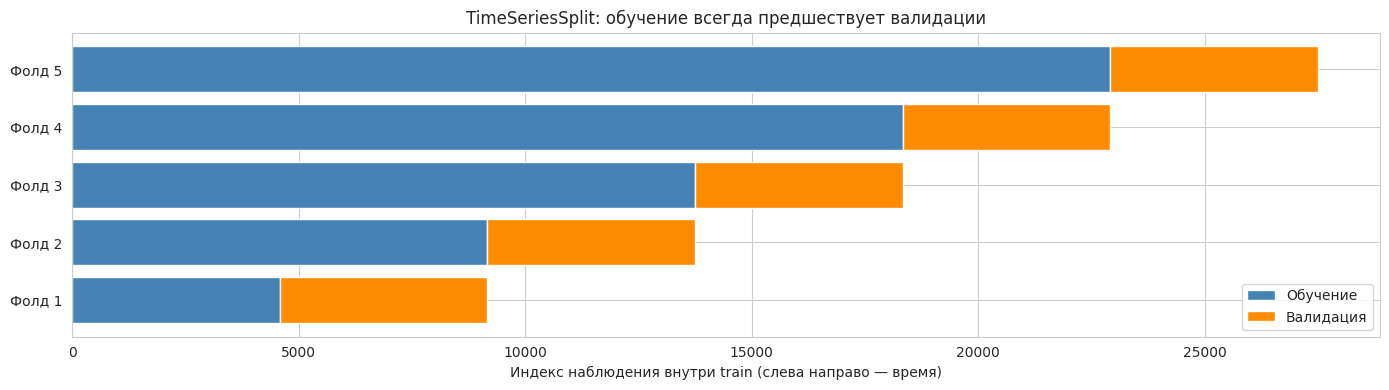

In [42]:
split_index = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
target_dates_train = df['Target_Date'].iloc[:split_index]
target_dates_test = df['Target_Date'].iloc[split_index:]
target_load_type_test = df['Target_Load_Type'].iloc[split_index:]

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train target period:', target_dates_train.min(), '—', target_dates_train.max())
print('Test target period: ', target_dates_test.min(), '—', target_dates_test.max())
assert target_dates_train.max() < target_dates_test.min()

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

tscv_scheme = TimeSeriesSplit(n_splits=5)
fig, ax = plt.subplots(figsize=(14,4))
for i,(tr,va) in enumerate(tscv_scheme.split(X_train)):
    ax.barh(i, len(tr), left=tr[0], color='steelblue', label='Обучение' if i==0 else None)
    ax.barh(i, len(va), left=va[0], color='darkorange', label='Валидация' if i==0 else None)
ax.set_yticks(range(5), [f'Фолд {i+1}' for i in range(5)])
ax.set_xlabel('Индекс наблюдения внутри train (слева направо — время)')
ax.set_title('TimeSeriesSplit: обучение всегда предшествует валидации')
ax.legend()
plt.tight_layout(); plt.show()

### Вывод по шагу 26 — обучение и тест разделены по времени

| Выборка | Наблюдений | Доля |
|---|---:|---:|
| Train | **27 493** | **80%** |
| Test | **6 874** | **20%** |

Целевые даты train: **08.01.2018 00:30 — 21.10.2018 09:30**. Тест начинается позже: **21.10.2018 09:45** и заканчивается **01.01.2019 00:00**.

Такое разделение имитирует реальное применение: модель обучается на прошлом и проверяется на последующем периоде. Случайное перемешивание здесь было бы некорректно, потому что часть более поздних наблюдений могла бы попасть в обучение раньше, чем модель проверяется на прошлом.

`TimeSeriesSplit` дополнительно делит train на последовательные фолды: в каждом фолде обучающий отрезок расположен раньше валидационного. Финальный тест сохраняется для заключительной проверки.

## Шаг 27. Метрики качества и сравнение масштабирования

Перед обучением фиксируем смысл метрик. MAE — средний модуль ошибки в исходных единицах; RMSE сильнее штрафует крупные ошибки; R² сравнивает модель с простым прогнозом средним. Масштабирование проверяем на линейной регрессии, поскольку модели на деревьях менее чувствительны к единицам шкалы.

In [43]:
def make_preprocessor(scaler):
    """ColumnTransformer с выбранным способом масштабирования числовых признаков."""
    return ColumnTransformer(transformers=[
        ('num', scaler, numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

scaling_variants = {
    'Без масштабирования': 'passthrough',
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler()
}

tscv5 = TimeSeriesSplit(n_splits=5)
scaling_rows = []
for name, scaler in scaling_variants.items():
    pipe = Pipeline(steps=[
        ('preprocessor', make_preprocessor(scaler)),
        ('model', LinearRegression())
    ])
    cv = cross_validate(
        pipe, X_train, y_train, cv=tscv5,
        scoring={
            'MAE': 'neg_mean_absolute_error',
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        },
        n_jobs=1
    )
    scaling_rows.append({
        'Способ': name,
        'MAE (mean ± std)': f"{-cv['test_MAE'].mean():.3f} ± {cv['test_MAE'].std():.3f}",
        'RMSE (mean ± std)': f"{-cv['test_RMSE'].mean():.3f} ± {cv['test_RMSE'].std():.3f}",
        'R2 (mean ± std)': f"{cv['test_R2'].mean():.4f} ± {cv['test_R2'].std():.4f}"
    })

scaling_results = pd.DataFrame(scaling_rows)
scaling_results

,Способ,MAE (mean ± std),RMSE (mean ± std),R2 (mean ± std)
0,Без масштабирования,7.388 ± 0.797,12.837 ± 0.811,0.8355 ± 0.0111
1,StandardScaler,7.388 ± 0.797,12.837 ± 0.811,0.8355 ± 0.0111
2,MinMaxScaler,7.388 ± 0.797,12.837 ± 0.811,0.8355 ± 0.0111


In [44]:
# Влияние масштабирования на коэффициенты линейной регрессии
coef_rows = []
coef_details = {}
for name, scaler in scaling_variants.items():
    pipe = Pipeline(steps=[
        ('preprocessor', make_preprocessor(scaler)),
        ('model', LinearRegression())
    ])
    pipe.fit(X_train, y_train)
    coefs = pipe.named_steps['model'].coef_
    coef_rows.append({
        'Способ': name,
        'Число коэффициентов': len(coefs),
        'Макс. |коэффициент|': np.abs(coefs).max(),
        'Средний |коэффициент|': np.abs(coefs).mean()
    })
    coef_details[name] = pd.Series(
        coefs,
        index=pipe.named_steps['preprocessor'].get_feature_names_out()
    )

pd.DataFrame(coef_rows)

,Способ,Число коэффициентов,Макс. |коэффициент|,Средний |коэффициент|
0,Без масштабирования,35,136.113721,4.319693
1,StandardScaler,35,26.273738,1.736062
2,MinMaxScaler,35,117.457225,6.548252


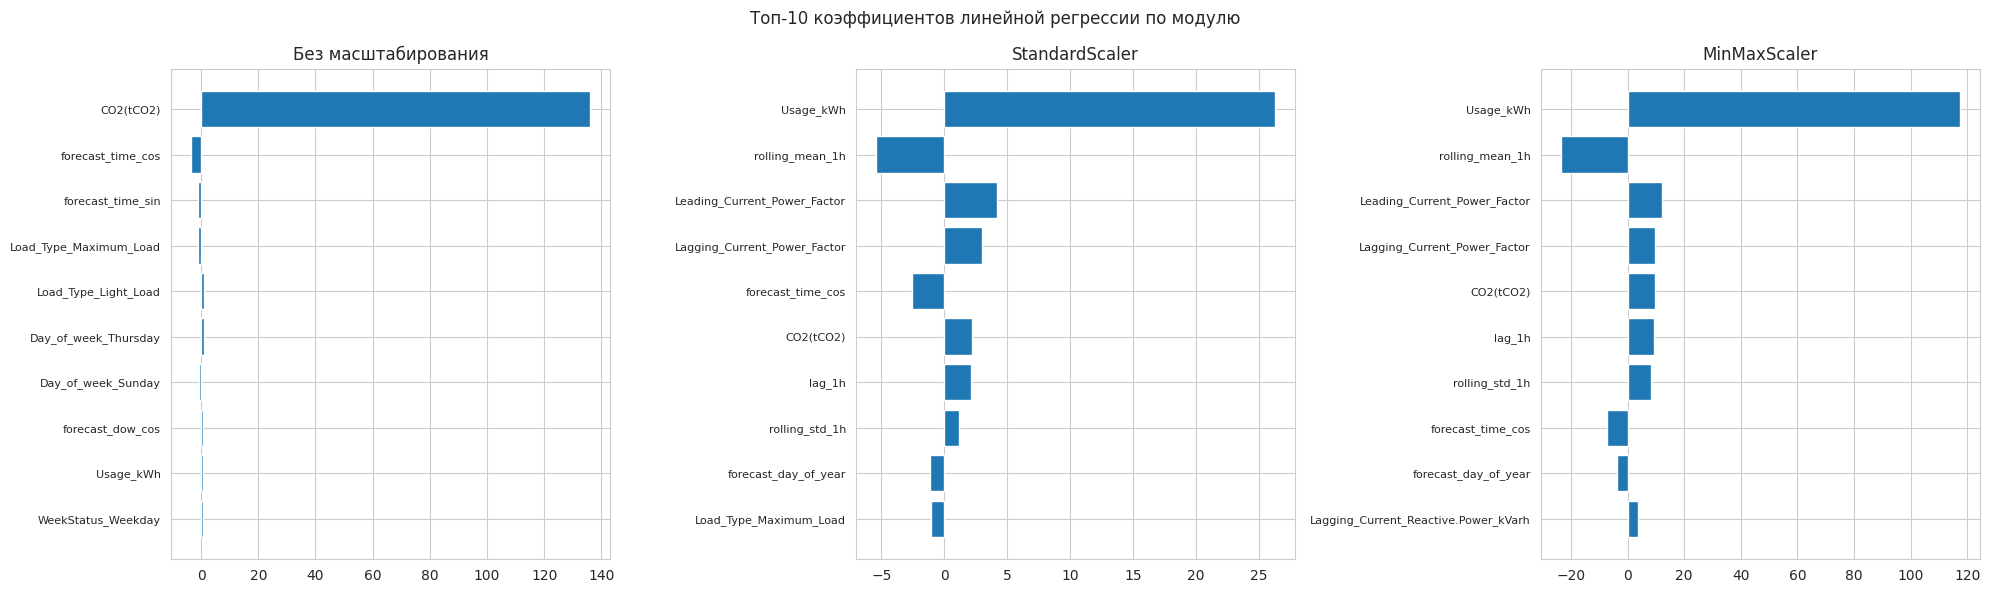

In [45]:
# Топ-10 коэффициентов по модулю для каждого варианта
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)
for ax, (name, coef_s) in zip(axes, coef_details.items()):
    top = coef_s.reindex(coef_s.abs().sort_values(ascending=False).index)[:10]
    ax.barh(range(len(top)), top.values)
    ax.set_yticks(range(len(top)),
                  [i.replace('num__', '').replace('cat__', '') for i in top.index],
                  fontsize=8)
    ax.invert_yaxis()
    ax.set_title(name)
plt.suptitle('Топ-10 коэффициентов линейной регрессии по модулю')
plt.tight_layout()
plt.show()

### Вывод по шагу 27 — масштабирование изменило коэффициенты, но не качество линейной модели

На пяти временных фолдах линейная регрессия показала одинаковые метрики во всех трёх вариантах:

| Масштабирование | MAE, среднее ± std | RMSE, среднее ± std | R², среднее ± std |
|---|---:|---:|---:|
| Без масштабирования | **7,388 ± 0,797** | **12,837 ± 0,811** | **0,8355 ± 0,0111** |
| `StandardScaler` | **7,388 ± 0,797** | **12,837 ± 0,811** | **0,8355 ± 0,0111** |
| `MinMaxScaler` | **7,388 ± 0,797** | **12,837 ± 0,811** | **0,8355 ± 0,0111** |

**Почему качество не изменилось:** используется обычная линейная регрессия без штрафа-регуляризации. Масштабирование меняет единицы и численные значения коэффициентов, но при обратном преобразовании не обязано менять сами прогнозы.

Например, максимальный модуль коэффициента составил **136,11** без масштабирования и **26,27** после `StandardScaler`. Это не означает, что второй вариант хуже или лучше: коэффициенты выражены в разных шкалах, поэтому их нельзя напрямую сравнивать по абсолютной величине.

**Напоминание о метриках:** MAE — средний модуль ошибки в кВт·ч; RMSE сильнее штрафует крупные промахи; R² = 1 соответствует идеальному прогнозу, R² = 0 — уровню постоянного прогноза средним по train, отрицательный R² — результату хуже такого ориентира. R² не является процентом точных предсказаний.

## Шаг 28. Baseline и линейная регрессия

Сначала строим два простых ориентира. Наивный прогноз предполагает, что следующие 15 минут будут такими же, как текущие. Линейная регрессия проверяет, насколько хорошо цель объясняется линейной комбинацией измерений, календаря и лагов.

In [46]:
def evaluate(y_true, y_pred):
    """Возвращает (MAE, RMSE, R2) — единая функция оценки для всех моделей."""
    return (
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        r2_score(y_true, y_pred)
    )

def print_metrics(name, metrics):
    print(f'{name}:')
    print(f'  MAE:  {metrics[0]:.4f}')
    print(f'  RMSE: {metrics[1]:.4f}')
    print(f'  R²:   {metrics[2]:.4f}')

# --- Наивный прогноз ---
y_pred_naive = X_test['Usage_kWh'].values
m_naive = evaluate(y_test, y_pred_naive)
print_metrics('Naive Forecast', m_naive)

# --- Линейная регрессия (единый пайплайн: предобработка + модель) ---
lr_pipe = Pipeline(steps=[
    ('preprocessor', make_preprocessor(StandardScaler())),
    ('model', LinearRegression())
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
m_lr = evaluate(y_test, y_pred_lr)
print()
print_metrics('Linear Regression', m_lr)

Naive Forecast:
  MAE:  5.4395
  RMSE: 12.3202
  R²:   0.8463

Linear Regression:
  MAE:  6.7302
  RMSE: 11.7108
  R²:   0.8611


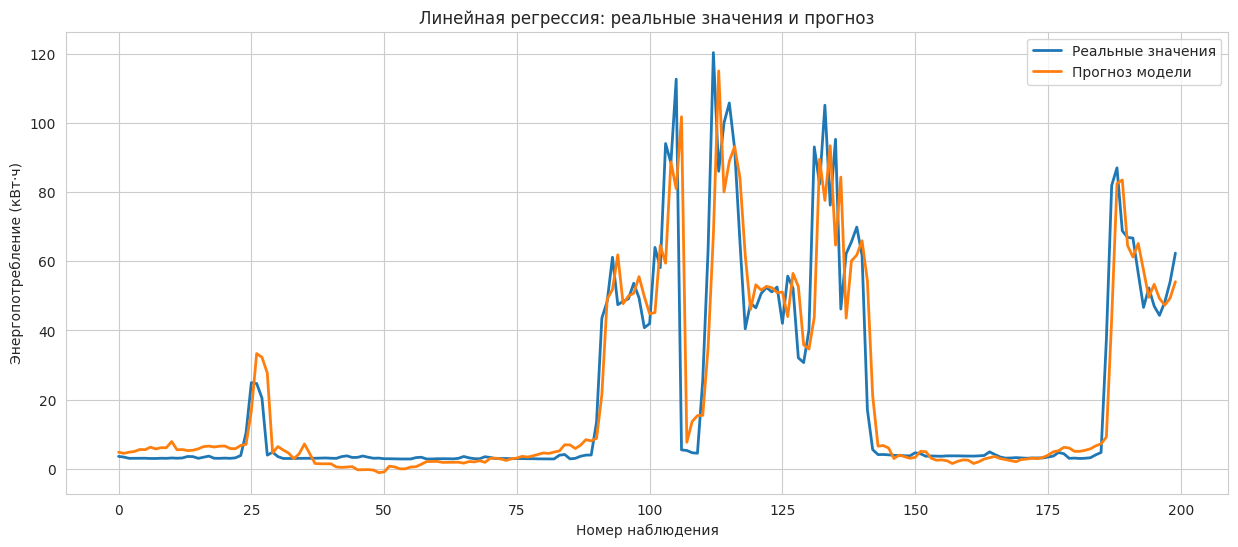

In [47]:
plt.figure(figsize=(15, 6))
plt.plot(y_test.iloc[:200].values, label='Реальные значения', linewidth=2)
plt.plot(y_pred_lr[:200], label='Прогноз модели', linewidth=2)
plt.title('Линейная регрессия: реальные значения и прогноз')
plt.xlabel('Номер наблюдения')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.legend()
plt.show()

### Вывод по шагу 28 — наивный прогноз оказался сильнее линейной регрессии по MAE

| Модель | MAE, кВт·ч | RMSE, кВт·ч | R² |
|---|---:|---:|---:|
| Наивный прогноз (`следующее = текущее`) | **5,440** | 12,320 | 0,846 |
| Линейная регрессия | **6,730** | **11,711** | **0,861** |

Наивная модель просто переносит текущее потребление на следующий интервал. Её MAE — 5,44 кВт·ч — является важным ориентиром: сложная модель должна показать более низкую ошибку.

Линейная регрессия имеет MAE на **23,7% выше**, то есть в среднем по модулю ошибается сильнее. Но её RMSE немного ниже (11,71 против 12,32), а R² выше (0,861 против 0,846). Это не противоречие: разные метрики по-разному взвешивают ошибки. Линейная модель могла уменьшить часть крупных промахов, одновременно увеличив типичную абсолютную ошибку.

**Промежуточный вывод:** простой перенос текущего значения — сильный baseline. Линейная комбинация признаков не дала выигрыша по основной метрике MAE, поэтому проверяем модели, способные улавливать нелинейные зависимости.

## Шаг 29. Random Forest: базовая модель и подбор параметров

Random Forest усредняет прогнозы множества деревьев. Он способен учитывать нелинейные зависимости и взаимодействия между признаками. Проверяем базовую конфигурацию, затем ограниченный RandomizedSearchCV на первом временном фрагменте train. После выбора параметров модель переобучается на всей обучающей части.

In [48]:
# --- Random Forest с умеренной конфигурацией для базового сравнения ---
rf_default = Pipeline(steps=[
    ('preprocessor', make_preprocessor(StandardScaler())),
    ('model', RandomForestRegressor(
        n_estimators=60, max_depth=14, min_samples_leaf=2,
        max_features=0.5, random_state=SEED, n_jobs=2
    ))
])
rf_default.fit(X_train, y_train)
m_rf_default = evaluate(y_test, rf_default.predict(X_test))
print_metrics('Random Forest (базовая конфигурация)', m_rf_default)

Random Forest (базовая конфигурация):
  MAE:  4.1189
  RMSE: 8.6626
  R²:   0.9240


In [49]:
# --- Подбор гиперпараметров Random Forest случайным поиском ---
# Для настройки используем первый временной фрагмент train; следующий блок оставляем для независимой CV-проверки.
# После выбора параметров модель будет переобучена на всём X_train.
rf_tune_size = min(4000, len(X_train))
X_rf_tune = X_train.iloc[:rf_tune_size]
y_rf_tune = y_train.iloc[:rf_tune_size]

param_distributions = {
    'model__n_estimators': [60, 100],
    'model__max_depth': [10, 14, None],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.5]
}

rf_search = RandomizedSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', make_preprocessor(StandardScaler())),
        ('model', RandomForestRegressor(random_state=SEED, n_jobs=1))
    ]),
    param_distributions=param_distributions,
    n_iter=2,
    scoring='neg_mean_absolute_error',
    cv=TimeSeriesSplit(n_splits=2),
    random_state=SEED,
    n_jobs=1,
    verbose=1
)
rf_search.fit(X_rf_tune, y_rf_tune)

print('Размер фрагмента для подбора:', len(X_rf_tune))
print('Лучшие параметры:', rf_search.best_params_)
print(f'Лучший MAE на временной CV-фрагменте: {-rf_search.best_score_:.4f}')

# Фиксируем выбранные параметры и обучаем итоговый RF на всём train.
rf_best = rf_search.best_estimator_
rf_best.named_steps['model'].set_params(n_jobs=2)
rf_best.fit(X_train, y_train)
y_pred_rf = rf_best.predict(X_test)
m_rf = evaluate(y_test, y_pred_rf)
print()
print_metrics('Random Forest (после подбора и обучения на всём train)', m_rf)
print(f'Прирост MAE относительно базовой версии: '
      f'{(m_rf_default[0] - m_rf[0]) / m_rf_default[0] * 100:.2f}%')

Fitting 2 folds for each of 2 candidates, totalling 4 fits


Размер фрагмента для подбора: 4000
Лучшие параметры: {'model__n_estimators': 100, 'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_depth': None}
Лучший MAE на временной CV-фрагменте: 7.7796



Random Forest (после подбора и обучения на всём train):
  MAE:  4.1017
  RMSE: 8.6682
  R²:   0.9239
Прирост MAE относительно базовой версии: 0.42%


### Вывод по шагу 29 — Random Forest уже был сильным до настройки

| Вариант | MAE, кВт·ч | RMSE, кВт·ч | R² |
|---|---:|---:|---:|
| Базовый Random Forest | 4,119 | **8,663** | 0,924 |
| Random Forest после настройки | **4,102** | 8,668 | 0,924 |

Настройка снизила MAE всего на **0,42%**. Это очень небольшой прирост: RMSE слегка ухудшилась, а R² практически не изменился. Следовательно, нельзя утверждать, что поиск параметров радикально улучшил модель — основное качество уже обеспечивала сама модель Random Forest и выбранные признаки.

Для настройки использовано **4 000 строк** раннего фрагмента train, проверено **2 набора параметров** на двух временных фолдах (всего 4 обучения в поиске). Лучший набор: `n_estimators=100`, `min_samples_leaf=4`, `max_features=0.5`, `max_depth=None`. После выбора параметров модель переобучена на всех **27 493** обучающих наблюдениях.

**Ограничение:** поиск был компактным, а не исчерпывающим. Итоговую роль модели определяем не по одному поиску, а по отдельной временной кросс-валидации.

## Шаг 30. CatBoost: базовая конфигурация и ранняя остановка

CatBoost — градиентный бустинг над деревьями. Для настройки числа итераций выделяем внутренний временной хвост обучающего периода: модель обучается на ранней части, а ранняя остановка отслеживает ошибку на следующем отрезке. Затем фиксируем число итераций и обучаем финальный вариант на всей train-части.

In [50]:
# Для настройки CatBoost берём ранний фрагмент train; следующий временной блок используется для отдельной CV-проверки.
# Финальная модель позднее обучается на всём X_train.
cat_tune_size = min(4000, len(X_train))
X_cat_tune = X_train.iloc[:cat_tune_size]
y_cat_tune = y_train.iloc[:cat_tune_size]
inner_cut = int(len(X_cat_tune) * 0.8)
X_tr, X_val = X_cat_tune.iloc[:inner_cut], X_cat_tune.iloc[inner_cut:]
y_tr, y_val = y_cat_tune.iloc[:inner_cut], y_cat_tune.iloc[inner_cut:]

print('Фрагмент для настройки:', len(X_cat_tune), 'наблюдений')
print('Внутреннее обучение:', len(X_tr), '| валидация:', len(X_val))

catboost_default_validation = CatBoostRegressor(
    iterations=60,
    depth=6,
    learning_rate=0.05,
    loss_function='RMSE',
    eval_metric='MAE',
    random_seed=SEED,
    early_stopping_rounds=10,
    thread_count=1,
    allow_writing_files=False,
    verbose=False
)
catboost_default_validation.fit(
    X_tr, y_tr,
    cat_features=categorical_features,
    eval_set=(X_val, y_val),
    verbose=False
)

iterations_default = max(1, catboost_default_validation.get_best_iteration() + 1)
catboost_default = CatBoostRegressor(
    iterations=iterations_default,
    depth=6,
    learning_rate=0.05,
    loss_function='RMSE',
    eval_metric='MAE',
    random_seed=SEED,
    thread_count=1,
    allow_writing_files=False,
    verbose=False
)
catboost_default.fit(
    X_train, y_train,
    cat_features=categorical_features,
    verbose=False
)
y_pred_cb_default = catboost_default.predict(X_test)
m_cb_default = evaluate(y_test, y_pred_cb_default)

print('Число итераций выбрано на внутренней валидации:', iterations_default)
print_metrics('CatBoost (базовая конфигурация, обучение на всём train)', m_cb_default)

Фрагмент для настройки: 4000 наблюдений
Внутреннее обучение: 3200 | валидация: 800


Число итераций выбрано на внутренней валидации: 59
CatBoost (базовая конфигурация, обучение на всём train):
  MAE:  5.2484
  RMSE: 9.6787
  R²:   0.9051


### Вывод по шагу 30 — базовый CatBoost уступил Random Forest на тестовом отрезке

На внутренней временной валидации ранняя остановка выбрала **59 итераций**. Итерация — очередное дерево, добавленное в ансамбль. После фиксации этого числа CatBoost обучен на всей train-выборке.

Результат базового CatBoost на тесте: **MAE = 5,248 кВт·ч**, **RMSE = 9,679 кВт·ч**, **R² = 0,905**. Это лучше наивного baseline по MAE (5,440), но хуже настроенного Random Forest (MAE 4,102).

CatBoost имеет преимущество в обработке категориальных переменных и способен находить нелинейные зависимости. Однако сложность алгоритма сама по себе не гарантирует лидерства: качество определяется фактическими метриками на корректном временном разбиении.

## Шаг 31. Настройка CatBoost с помощью Optuna

Optuna подбирает глубину деревьев, скорость обучения, L2-регуляризацию и случайность разбиений. Цель поиска — минимизировать MAE на внутреннем временном валидационном отрезке раннего блока train. Важно: поиск не должен обращаться к финальному тесту.

In [51]:
def objective(trial):
    """Подбор CatBoost по MAE внутренней временной валидации."""
    params = {
        'depth': trial.suggest_int('depth', 4, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.015, 0.15, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'random_strength': trial.suggest_float('random_strength', 0.0, 2.0)
    }
    model = CatBoostRegressor(
        iterations=60,
        loss_function='RMSE',
        eval_metric='MAE',
        random_seed=SEED,
        early_stopping_rounds=10,
        thread_count=1,
        allow_writing_files=False,
        verbose=False,
        **params
    )
    model.fit(
        X_tr, y_tr,
        cat_features=categorical_features,
        eval_set=(X_val, y_val),
        verbose=False
    )
    best_iteration = max(0, int(model.get_best_iteration()))
    trial.set_user_attr('best_iteration', best_iteration)
    prediction = model.predict(X_val)
    return mean_absolute_error(y_val, prediction)

study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=2, show_progress_bar=False)

print('Лучшие параметры:', study.best_params)
print(f'Лучший MAE на внутренней валидации: {study.best_value:.4f}')
print('Лучшая итерация:', study.best_trial.user_attrs.get('best_iteration'))

Лучшие параметры: {'depth': 5, 'learning_rate': 0.1339077045653044, 'l2_leaf_reg': 7.587945476302646, 'random_strength': 1.1973169683940732}
Лучший MAE на внутренней валидации: 5.2716
Лучшая итерация: 56


In [52]:
# Число итераций определено на внутренней валидации; финальную модель
# обучаем на всей обучающей выборке, не используя тестовую часть.
iterations_tuned = max(1, int(study.best_trial.user_attrs['best_iteration']) + 1)
catboost_tuned = CatBoostRegressor(
    iterations=iterations_tuned,
    loss_function='RMSE',
    eval_metric='MAE',
    random_seed=SEED,
    thread_count=1,
    allow_writing_files=False,
    verbose=False,
    **study.best_params
)
catboost_tuned.fit(
    X_train, y_train,
    cat_features=categorical_features,
    verbose=False
)
y_pred_cb = catboost_tuned.predict(X_test)
m_cb = evaluate(y_test, y_pred_cb)

print('Число итераций финальной модели:', iterations_tuned)
print_metrics('CatBoost (после Optuna, обучение на всём train)', m_cb)
print(f'Изменение MAE относительно базовой конфигурации: '
      f'{(m_cb_default[0] - m_cb[0]) / m_cb_default[0] * 100:.2f}%')

Число итераций финальной модели: 57
CatBoost (после Optuna, обучение на всём train):
  MAE:  4.5933
  RMSE: 8.8668
  R²:   0.9204
Изменение MAE относительно базовой конфигурации: 12.48%


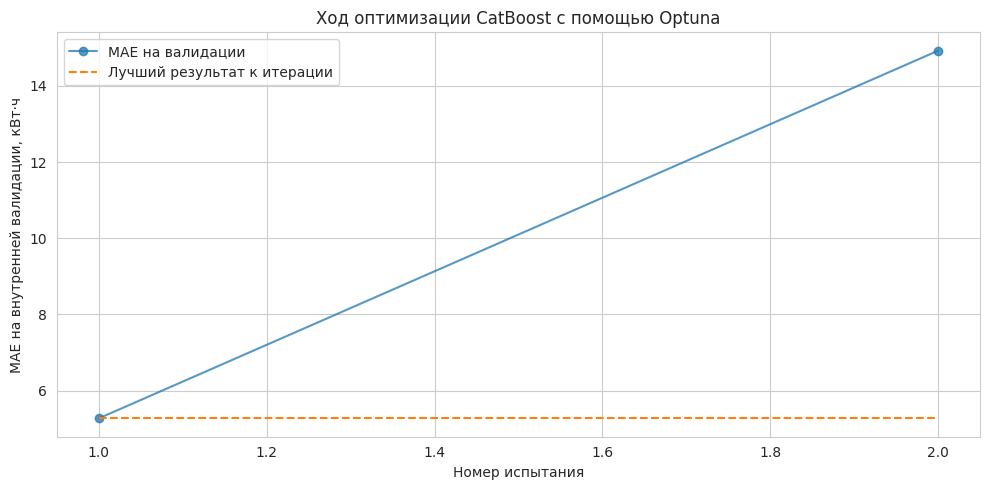

In [53]:
trial_values = [trial.value for trial in study.trials if trial.value is not None]
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(trial_values) + 1), trial_values, marker='o', alpha=0.75, label='MAE на валидации')
plt.plot(
    range(1, len(trial_values) + 1),
    np.minimum.accumulate(trial_values),
    linestyle='--',
    label='Лучший результат к итерации'
)
plt.title('Ход оптимизации CatBoost с помощью Optuna')
plt.xlabel('Номер испытания')
plt.ylabel('MAE на внутренней валидации, кВт·ч')
plt.legend()
plt.tight_layout()
plt.show()

### Вывод по шагу 31 — Optuna улучшила CatBoost, но поиск был небольшим

Выполнено **2 испытания Optuna** — ровно столько указано в `n_trials=2`. Для каждого набора параметров модель оценивалась на одном и том же внутреннем временном validation-отрезке.

| Показатель | Результат |
|---|---:|
| Лучшая MAE на внутренней валидации | **5,272 кВт·ч** |
| Число итераций финальной модели | **57** |
| MAE CatBoost до настройки на тесте | 5,248 кВт·ч |
| MAE CatBoost после настройки на тесте | **4,593 кВт·ч** |
| Изменение MAE относительно базового CatBoost | **−12,48%** |

Отрицательное изменение MAE означает, что ошибка уменьшилась; в данном случае настроенный CatBoost улучшил базовую версию. Его тестовый RMSE — 8,867 кВт·ч, R² — 0,920.

Лучшие найденные параметры: `depth=5`, `learning_rate≈0,134`, `l2_leaf_reg≈7,588`, `random_strength≈1,197`. При этом **двух испытаний недостаточно, чтобы считать конфигурацию оптимальной**: это предварительный поиск для учебного эксперимента. Модель всё равно будет сравниваться с Random Forest на независимых временных фолдах train.

## Шаг 32. Эксперимент: нужен ли модели признак CO₂

Сравним две модели CatBoost на одном и том же внутреннем временном validation-фрагменте: одна получает текущий `CO2(tCO2)`, другая — нет. Такой эксперимент проверяет добавочную предсказательную пользу признака и не использует финальный тест для принятия решения.

In [54]:
features_without_co2 = [f for f in features if f != 'CO2(tCO2)']
categorical_without_co2 = [f for f in categorical_features if f in features_without_co2]

co2_val_model = CatBoostRegressor(
    iterations=iterations_tuned, loss_function='RMSE', eval_metric='MAE',
    random_seed=SEED, thread_count=1, allow_writing_files=False, verbose=False,
    **study.best_params
)
no_co2_val_model = CatBoostRegressor(
    iterations=iterations_tuned, loss_function='RMSE', eval_metric='MAE',
    random_seed=SEED, thread_count=1, allow_writing_files=False, verbose=False,
    **study.best_params
)
co2_val_model.fit(X_tr[features], y_tr, cat_features=categorical_features, verbose=False)
no_co2_val_model.fit(X_tr[features_without_co2], y_tr, cat_features=categorical_without_co2, verbose=False)
pred_co2_val = co2_val_model.predict(X_val[features])
pred_no_co2_val = no_co2_val_model.predict(X_val[features_without_co2])
mae_co2_val = mean_absolute_error(y_val, pred_co2_val)
mae_no_co2_val = mean_absolute_error(y_val, pred_no_co2_val)
co2_ablation_validation = pd.DataFrame([
    {'Вариант': 'CO₂ включён', 'MAE validation': mae_co2_val},
    {'Вариант': 'CO₂ исключён', 'MAE validation': mae_no_co2_val}
])
display(co2_ablation_validation.round(4))
print('Изменение MAE при исключении CO₂:', round(mae_no_co2_val-mae_co2_val,4), 'кВт·ч')

,Вариант,MAE validation
0,CO₂ включён,5.2716
1,CO₂ исключён,5.5028


Изменение MAE при исключении CO₂: 0.2312 кВт·ч


In [55]:
delta_co2_validation = mae_no_co2_val - mae_co2_val
co2_verdict = 'улучшает прогноз на этом validation-фрагменте' if delta_co2_validation > 0 else ('не даёт улучшения в этой конфигурации' if delta_co2_validation == 0 else 'ухудшает прогноз на этом validation-фрагменте')

### Вывод по шагу 32 — текущий CO₂ улучшил CatBoost на внутренней валидации

| Вариант модели | MAE на validation |
|---|---:|
| С текущим `CO2(tCO2)` | **5,272 кВт·ч** |
| Без `CO2(tCO2)` | 5,503 кВт·ч |

При исключении CO₂ MAE увеличилась на **0,231 кВт·ч**, или примерно на **4,2%** относительно варианта без признака. На этом внутреннем временном отрезке текущий CO₂ добавил прогнозную информацию.

Это не доказательство физической причинности и не гарантия такой же пользы на другом заводе или периоде. Признак имеет только 8 уникальных уровней и сильно связан с текущим потреблением; если метод его расчёта изменится, его ценность может измениться. Поэтому при переносе решения признак следует проверять заново.

## Шаг 33. Временная кросс-валидация и выбор модели на train

Теперь сравним четыре заранее выбранных варианта на последовательных фолдах внутри train: наивный прогноз, линейную регрессию, Random Forest и настроенный CatBoost. Победителя выбираем по средней MAE кросс-валидации, не по результату теста. Тестовый период останется независимой финальной проверкой.

*Примечание:* для разумного времени исполнения два последовательных фолда строятся на следующих 8 000 строках обучающей части после 4 000 строк, использованных для настройки. Это меньше полного train, поэтому разброс CV трактуем как дополнительную оценку на недавнем участке, а не как гарантию устойчивости на всех возможных режимах.

In [56]:
# Для контроля вычислительного времени проверяем последние 8 000 train-наблюдений.
# Это временной блок внутри обучающей выборки; тестовый период не затрагивается.
cv_start = min(4000, len(X_train) - 2)
cv_size = min(8000, len(X_train) - cv_start)
X_cv = X_train.iloc[cv_start:cv_start + cv_size].copy()
y_cv = y_train.iloc[cv_start:cv_start + cv_size].copy()
cv_splitter = TimeSeriesSplit(n_splits=2)
cv_rows = []
cv_fold_details = []

for fold, (tr_idx, va_idx) in enumerate(cv_splitter.split(X_cv), start=1):
    X_tr_fold, X_va_fold = X_cv.iloc[tr_idx], X_cv.iloc[va_idx]
    y_tr_fold, y_va_fold = y_cv.iloc[tr_idx], y_cv.iloc[va_idx]
    pred_naive_fold = X_va_fold['Usage_kWh'].to_numpy()
    cv_fold_details.append({'Model':'Naive Forecast','Fold':fold,
                             'MAE':mean_absolute_error(y_va_fold,pred_naive_fold),
                             'RMSE':np.sqrt(mean_squared_error(y_va_fold,pred_naive_fold)),
                             'R2':r2_score(y_va_fold,pred_naive_fold)})
    lr_fold = clone(lr_pipe)
    lr_fold.fit(X_tr_fold,y_tr_fold)
    pred = lr_fold.predict(X_va_fold)
    cv_fold_details.append({'Model':'Linear Regression','Fold':fold,
                             'MAE':mean_absolute_error(y_va_fold,pred),
                             'RMSE':np.sqrt(mean_squared_error(y_va_fold,pred)),
                             'R2':r2_score(y_va_fold,pred)})
    rf_fold = clone(rf_best)
    rf_fold.set_params(model__n_jobs=1)
    rf_fold.fit(X_tr_fold,y_tr_fold)
    pred = rf_fold.predict(X_va_fold)
    cv_fold_details.append({'Model':'Random Forest (tuned)','Fold':fold,
                             'MAE':mean_absolute_error(y_va_fold,pred),
                             'RMSE':np.sqrt(mean_squared_error(y_va_fold,pred)),
                             'R2':r2_score(y_va_fold,pred)})
    cb_fold = CatBoostRegressor(
        iterations=iterations_tuned, loss_function='RMSE', eval_metric='MAE',
        random_seed=SEED, thread_count=1, allow_writing_files=False,
        verbose=False, **study.best_params
    )
    cb_fold.fit(X_tr_fold,y_tr_fold,cat_features=categorical_features,verbose=False)
    pred = cb_fold.predict(X_va_fold)
    cv_fold_details.append({'Model':'CatBoost (Optuna)','Fold':fold,
                             'MAE':mean_absolute_error(y_va_fold,pred),
                             'RMSE':np.sqrt(mean_squared_error(y_va_fold,pred)),
                             'R2':r2_score(y_va_fold,pred)})

cv_detail = pd.DataFrame(cv_fold_details)
cv_summary = cv_detail.groupby('Model').agg(
    MAE_mean=('MAE','mean'), MAE_std=('MAE','std'),
    RMSE_mean=('RMSE','mean'), R2_mean=('R2','mean'), R2_std=('R2','std')
).sort_values('MAE_mean').reset_index()
display(cv_detail.round(4))
display(cv_summary.round(4))
cv_best_name = str(cv_summary.iloc[0]['Model'])
print(f'Независимый временной блок для CV: строки train с индекса {cv_start:,} по {cv_start+cv_size-1:,} ({cv_size:,} наблюдений).')
print('Модель, выбранная по минимальной средней MAE на TimeSeriesSplit:', cv_best_name)

,Model,Fold,MAE,RMSE,R2
0,Naive Forecast,1,6.2231,13.6431,0.8130
1,Linear Regression,1,7.7466,13.1607,0.8260
2,Random Forest (tuned),1,5.6748,10.8657,0.8814
3,CatBoost (Optuna),1,5.9852,10.9247,0.8801
4,Naive Forecast,2,6.3674,14.4423,0.8143
5,Linear Regression,2,7.4676,13.6346,0.8345
6,Random Forest (tuned),2,5.0371,10.5492,0.9009
7,CatBoost (Optuna),2,5.5285,10.7201,0.8977


,Model,MAE_mean,MAE_std,RMSE_mean,R2_mean,R2_std
0,Random Forest (tuned),5.3559,0.4509,10.7075,0.8912,0.0138
1,CatBoost (Optuna),5.7569,0.3229,10.8224,0.8889,0.0124
2,Naive Forecast,6.2953,0.1020,14.0427,0.8136,0.0009
3,Linear Regression,7.6071,0.1973,13.3976,0.8302,0.0060


Независимый временной блок для CV: строки train с индекса 4,000 по 11,999 (8,000 наблюдений).
Модель, выбранная по минимальной средней MAE на TimeSeriesSplit: Random Forest (tuned)


In [57]:
cv_best_row = cv_summary.iloc[0]
runner_up = cv_summary.iloc[1]

### Вывод по шагу 33 — по временной кросс-валидации лидирует Random Forest

| Модель | Средняя MAE, кВт·ч | Разброс MAE между фолдами |
|---|---:|---:|
| **Random Forest (tuned)** | **5,356** | ±0,451 |
| CatBoost (Optuna) | 5,757 | ±0,323 |
| Наивный прогноз | 6,295 | ±0,102 |
| Линейная регрессия | 7,607 | ±0,197 |

Random Forest показал наименьшую среднюю MAE. Его преимущество перед CatBoost составляет **0,401 кВт·ч на 15-минутный интервал**. По сравнению с наивным прогнозом средняя MAE меньше примерно на **14,9%** на выбранных CV-фолдах.

Стандартное отклонение после знака ± показывает разброс ошибки между фолдами: чем оно меньше, тем стабильнее результат между этими проверками. Но у Random Forest разброс немного выше, чем у CatBoost; небольшое преимущество по среднему не следует трактовать как абсолютное превосходство во всех режимах.

**Ограничение CV:** использован отдельный блок из **8 000 строк train** и только **2 последовательных фолда**; первые 4 000 строк этого блока не включены в CV, так как использовались для настройки. Поэтому это полезная независимая проверка внутри train, но не исчерпывающая оценка всех возможных периодов.

## Шаг 34. Финальная проверка моделей на отложенном тесте

После выбора модели по CV открываем последний 20%-ный период и сравниваем заранее обученные варианты на нём. Тестовая таблица теперь используется как финальная оценка обобщения, а не как способ выбрать победителя. В таблице отдельно показываем MAE, RMSE и R².

,Model,MAE,RMSE,R2,"Улучшение MAE к baseline, %"
0,Random Forest (tuned),4.1017,8.6682,0.9239,24.5955
1,CatBoost (Optuna),4.5933,8.8668,0.9204,15.5571
2,CatBoost (default),5.2484,9.6787,0.9051,3.5142
3,Naive Forecast,5.4395,12.3202,0.8463,0.0000
4,Linear Regression,6.7302,11.7108,0.8611,-23.7278


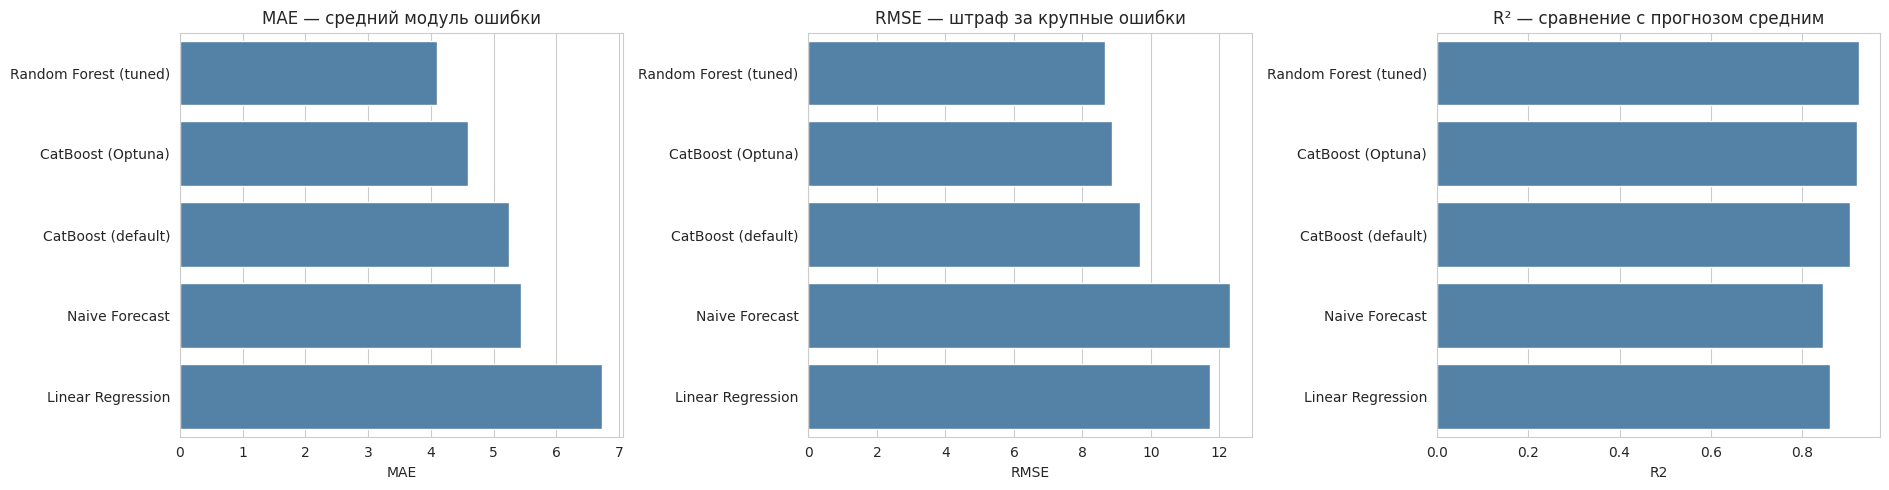

Выбор по CV: Random Forest (tuned)
Финальные тестовые показатели выбранной модели:
Model                          Random Forest (tuned)
MAE                                         4.101654
RMSE                                        8.668207
R2                                          0.923917
Улучшение MAE к baseline, %                24.595484


In [58]:
results = pd.DataFrame([
    {'Model':'Naive Forecast','MAE':m_naive[0],'RMSE':m_naive[1],'R2':m_naive[2]},
    {'Model':'Linear Regression','MAE':m_lr[0],'RMSE':m_lr[1],'R2':m_lr[2]},
    {'Model':'Random Forest (tuned)','MAE':m_rf[0],'RMSE':m_rf[1],'R2':m_rf[2]},
    {'Model':'CatBoost (default)','MAE':m_cb_default[0],'RMSE':m_cb_default[1],'R2':m_cb_default[2]},
    {'Model':'CatBoost (Optuna)','MAE':m_cb[0],'RMSE':m_cb[1],'R2':m_cb[2]}
])
results['Улучшение MAE к baseline, %'] = (m_naive[0]-results['MAE'])/m_naive[0]*100
results = results.sort_values('MAE').reset_index(drop=True)
display(results.round(4))

fig, axes = plt.subplots(1,3,figsize=(19,5))
for ax, metric, title in zip(axes,['MAE','RMSE','R2'],['MAE — средний модуль ошибки','RMSE — штраф за крупные ошибки','R² — сравнение с прогнозом средним']):
    sns.barplot(data=results.sort_values('MAE'),x=metric,y='Model',ax=ax,color='steelblue')
    ax.set_title(title); ax.set_xlabel(metric); ax.set_ylabel('')
plt.tight_layout(); plt.show()

prediction_by_model = {
    'Naive Forecast': X_test['Usage_kWh'].to_numpy(),
    'Linear Regression': y_pred_lr,
    'Random Forest (tuned)': y_pred_rf,
    'CatBoost (default)': y_pred_cb_default,
    'CatBoost (Optuna)': y_pred_cb
}
estimator_by_model = {
    'Naive Forecast':None,
    'Linear Regression':lr_pipe,
    'Random Forest (tuned)':rf_best,
    'CatBoost (default)':catboost_default,
    'CatBoost (Optuna)':catboost_tuned
}
features_by_model = {name:features for name in prediction_by_model}
best_model_name = cv_best_name
best_model_prediction = np.asarray(prediction_by_model[best_model_name])
best_model_object = estimator_by_model[best_model_name]
best_model_features = features_by_model[best_model_name]
best_model_row = results.loc[results['Model']==best_model_name].iloc[0]
best_model_mae = float(best_model_row['MAE'])
naive_mae = float(results.loc[results['Model']=='Naive Forecast','MAE'].iloc[0])
best_improvement = (naive_mae-best_model_mae)/naive_mae*100
assert len(best_model_prediction)==len(y_test)
print('Выбор по CV:',best_model_name)
print('Финальные тестовые показатели выбранной модели:')
print(best_model_row.to_string())

In [59]:
test_verdict = 'ниже' if best_model_mae < naive_mae else 'выше'

### Вывод по шагу 34 — финальная проверка на тесте подтверждает выбор Random Forest

Модель выбрана до просмотра тестовых результатов — по временной кросс-валидации. На отложенном более позднем периоде получено:

| Модель | MAE, кВт·ч | RMSE, кВт·ч | R² |
|---|---:|---:|---:|
| **Random Forest (tuned)** | **4,102** | 8,668 | **0,924** |
| CatBoost (Optuna) | 4,593 | **8,867** | 0,920 |
| CatBoost (default) | 5,248 | 9,679 | 0,905 |
| Наивный прогноз | 5,440 | 12,320 | 0,846 |
| Линейная регрессия | 6,730 | 11,711 | 0,861 |

Random Forest имеет наименьшую тестовую MAE среди проверенных вариантов. По сравнению с наивным прогнозом MAE уменьшилась на **24,6%**. R² = **0,924** означает, что модель объясняет большую часть изменчивости тестовой цели относительно простого прогноза средним, но это не означает 92,4% «точных ответов».

RMSE (**8,668**) более чем вдвое превышает MAE (**4,102**). Это указывает на влияние отдельных крупных промахов: большинство ошибок может быть умеренным, но редкие большие ошибки заметно увеличивают RMSE.

Тестовый период используется здесь для финальной проверки, а не для выбора победителя. Поэтому, даже если отдельная модель имеет близкий результат, решение о выборе сохраняется за train-CV.

## Шаг 35. Фактическое и прогнозируемое потребление

Накладываем прогноз и фактическое значение для выбранной по CV модели на фрагмент тестового периода. Совпадение линий говорит, что модель улавливает уровень и динамику; систематические расхождения показывают, где прогноз сглаживает пики или запаздывает.

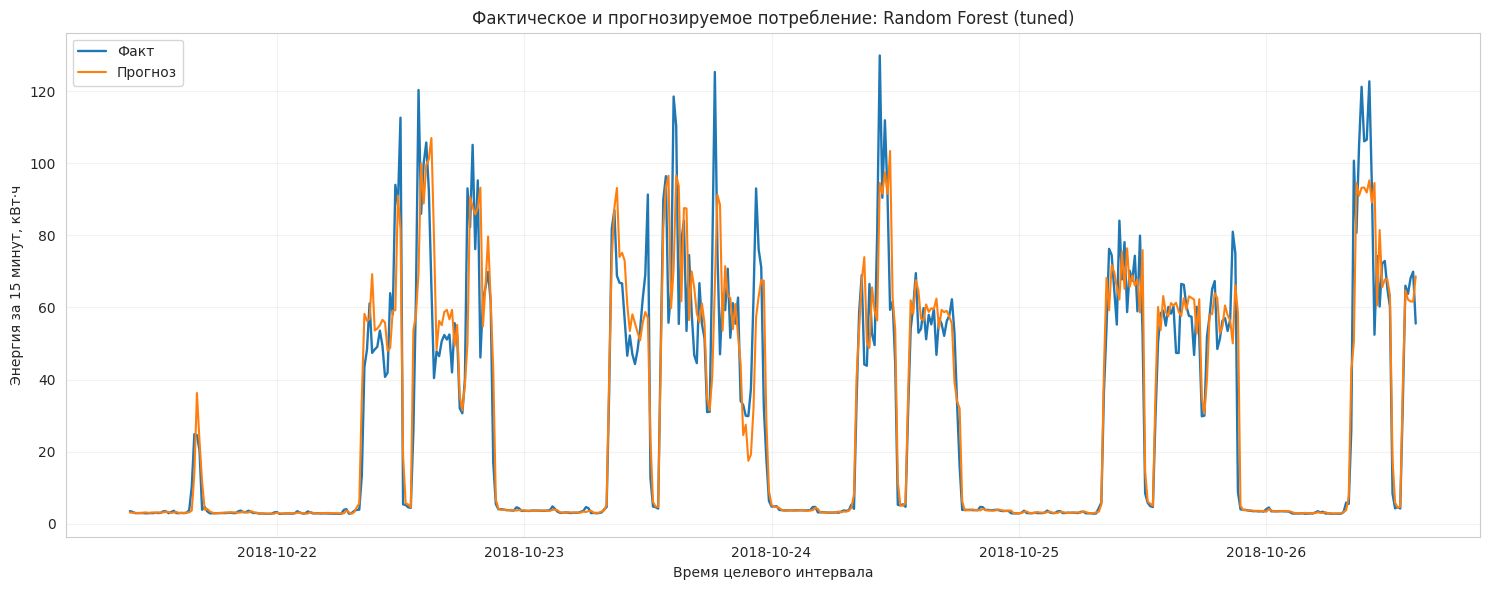

In [60]:
plot_n = min(500,len(y_test))
plt.figure(figsize=(15,6))
plt.plot(target_dates_test.iloc[:plot_n],y_test.iloc[:plot_n].values,label='Факт',linewidth=1.7)
plt.plot(target_dates_test.iloc[:plot_n],best_model_prediction[:plot_n],label='Прогноз',linewidth=1.5)
plt.title(f'Фактическое и прогнозируемое потребление: {best_model_name}')
plt.xlabel('Время целевого интервала'); plt.ylabel('Энергия за 15 минут, кВт·ч')
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

## Шаг 36. Распределение ошибок и систематическое смещение

Остаток определяем как `факт − прогноз`. Положительная ошибка означает недопрогноз, отрицательная — завышение. Среднее смещение показывает направление систематической ошибки, медиана — центральную ошибку, P90 абсолютной ошибки — уровень, ниже которого лежит 90% ошибок по модулю.

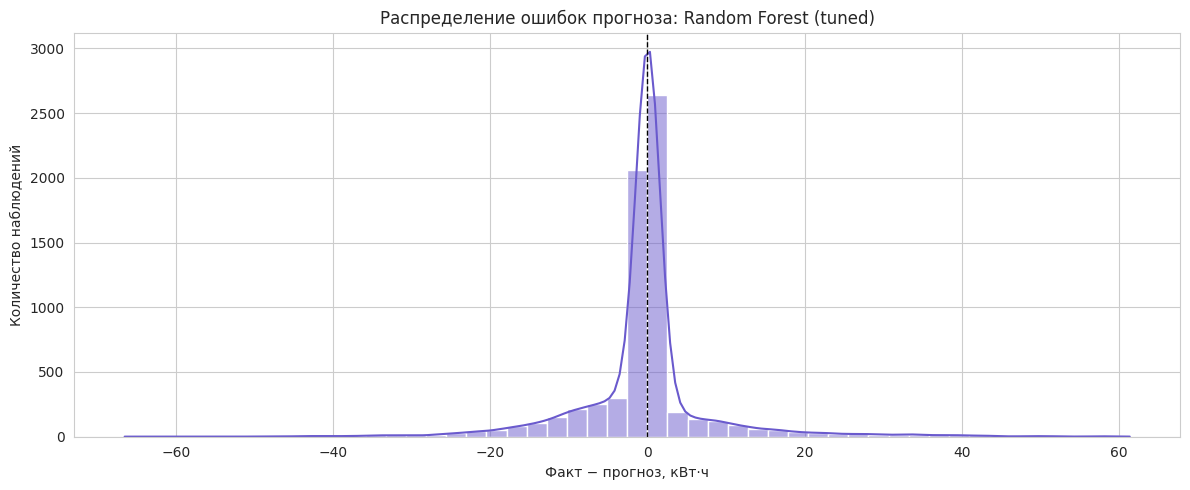

Выбранная модель: Random Forest (tuned)
Среднее смещение (факт − прогноз): -0.3362 кВт·ч
Стандартное отклонение ошибок: 8.6617 кВт·ч
MAE по тесту: 4.1017 кВт·ч
Доля наблюдений с |ошибка| < общей MAE: 72.8%


In [61]:
# Остаток = факт − прогноз. Положительный остаток означает недопрогноз.
errors = y_test.to_numpy() - best_model_prediction

plt.figure(figsize=(12, 5))
sns.histplot(errors, bins=50, kde=True, color='slateblue')
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.title(f'Распределение ошибок прогноза: {best_model_name}')
plt.xlabel('Факт − прогноз, кВт·ч')
plt.ylabel('Количество наблюдений')
plt.tight_layout()
plt.show()

print(f'Выбранная модель: {best_model_name}')
print(f'Среднее смещение (факт − прогноз): {errors.mean():.4f} кВт·ч')
print(f'Стандартное отклонение ошибок: {errors.std():.4f} кВт·ч')
print(f'MAE по тесту: {best_model_mae:.4f} кВт·ч')
print(f'Доля наблюдений с |ошибка| < общей MAE: {(np.abs(errors) < best_model_mae).mean():.1%}')

In [62]:
median_error = float(np.median(errors))
mean_abs_error = float(np.mean(np.abs(errors)))
p90_abs_error = float(np.quantile(np.abs(errors), 0.90))
under_share = float((errors > 0).mean())
over_share = float((errors < 0).mean())

### Вывод по шагу 36 — среднее смещение мало, но отдельные ошибки бывают крупными

Ошибка определена как **факт − прогноз**. Поэтому положительное значение означает недопрогноз, отрицательное — завышение прогноза.

| Показатель ошибки | Результат | Как читать |
|---|---:|---|
| Среднее смещение (bias) | **−0,336 кВт·ч** | В среднем модель немного завышает потребление |
| Медианная ошибка | **−0,012 кВт·ч** | Центральная ошибка почти равна нулю |
| MAE | **4,102 кВт·ч** | Средняя абсолютная ошибка |
| P90 абсолютной ошибки | **13,078 кВт·ч** | У 90% прогнозов ошибка по модулю не выше этого уровня |
| Стандартное отклонение ошибок | **8,662 кВт·ч** | Разброс остатков, чувствительный к крупным промахам |

Модель недооценила фактическое значение в **48,4%** случаев и завысила в **51,6%**. Эти доли описывают только направление ошибки, но не её величину.

Bias близок к нулю, однако это не означает, что прогнозы точны в каждом интервале: положительные и отрицательные ошибки могут взаимно компенсироваться. P90 существенно выше MAE, поэтому далее отдельно анализируем часы и высокие нагрузки.

## Шаг 37. Ошибки по времени суток и на пиковых нагрузках

Средняя ошибка по всему тесту может скрывать проблемные часы. Поэтому группируем ошибки по часу прогнозируемого интервала и отдельно оцениваем верхние 10% нагрузок. Время извлекаем через `DatetimeIndex(...).hour`: это работает надёжно и не вызывает ошибку `Series has no attribute hour`.

,hour,MAE,Bias,Observations
0,0,0.277,0.151,285
1,1,0.406,0.081,284
2,2,0.303,0.138,284
3,3,0.225,0.036,284
4,4,0.216,0.036,284
5,5,0.221,0.049,284
6,6,0.279,0.053,284
7,7,0.382,0.052,284
8,8,7.571,-2.165,284
9,9,9.002,0.259,285


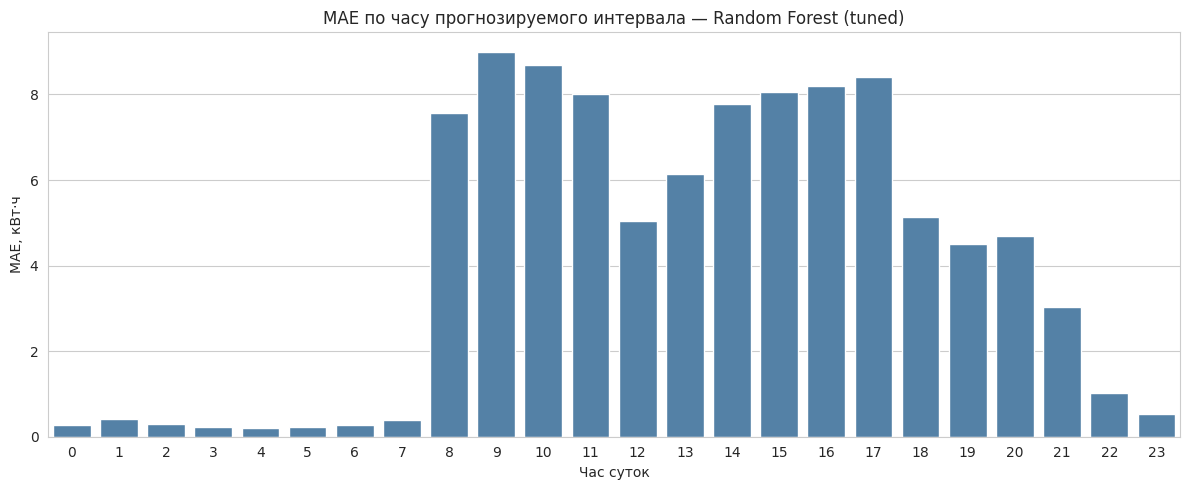

,"Порог по train, кВт·ч",Число тестовых наблюдений выше P90 train,"Доля теста, %",MAE на пиках,RMSE на пиках,Bias факт−прогноз
0,80.35,452,6.576,17.52,22.118,15.477


Доля тестовой выборки выше порога P90 train: 6.6%


In [63]:
error_analysis = pd.DataFrame({
    'target_date': pd.to_datetime(target_dates_test).to_numpy(),
    'actual': y_test.to_numpy(),
    'prediction': best_model_prediction,
    'error': errors
})
error_analysis['abs_error'] = error_analysis['error'].abs()
# Извлекаем час из коллекции временных меток, а не у объекта Series напрямую.
error_analysis['hour'] = pd.DatetimeIndex(pd.to_datetime(error_analysis['target_date'])).hour

hourly_errors = error_analysis.groupby('hour').agg(
    MAE=('abs_error','mean'), Bias=('error','mean'), Observations=('error','size')
).reset_index()
display(hourly_errors.round(3))

fig,ax=plt.subplots(figsize=(12,5))
sns.barplot(data=hourly_errors,x='hour',y='MAE',color='steelblue',ax=ax)
ax.set_title(f'MAE по часу прогнозируемого интервала — {best_model_name}')
ax.set_xlabel('Час суток'); ax.set_ylabel('MAE, кВт·ч'); plt.tight_layout(); plt.show()

peak_threshold = float(y_train.quantile(.90))
peak_mask = y_test.to_numpy() >= peak_threshold
if peak_mask.sum()==0:
    raise ValueError('На тесте нет наблюдений выше порога верхних 10% train.')
peak_mae = mean_absolute_error(y_test.to_numpy()[peak_mask],best_model_prediction[peak_mask])
peak_rmse = np.sqrt(mean_squared_error(y_test.to_numpy()[peak_mask],best_model_prediction[peak_mask]))
peak_bias = float((y_test.to_numpy()[peak_mask]-best_model_prediction[peak_mask]).mean())
peak_report = pd.DataFrame([{'Порог по train, кВт·ч':peak_threshold,
                             'Число тестовых наблюдений выше P90 train':int(peak_mask.sum()),
                             'Доля теста, %':peak_mask.mean()*100,
                             'MAE на пиках':peak_mae,'RMSE на пиках':peak_rmse,
                             'Bias факт−прогноз':peak_bias}])
display(peak_report.round(3))
print(f'Доля тестовой выборки выше порога P90 train: {peak_mask.mean():.1%}')

In [64]:
peak_error_ratio = peak_mae / best_model_mae if best_model_mae else np.nan
peak_direction = 'недооценивает' if peak_bias>0 else ('переоценивает' if peak_bias<0 else 'не имеет среднего смещения')
hour_max_error = hourly_errors.loc[hourly_errors['MAE'].idxmax()]
hour_min_error = hourly_errors.loc[hourly_errors['MAE'].idxmin()]

### Вывод по шагу 37 — главная слабость модели проявляется на высоких нагрузках

Порог пикового сегмента установлен как **P90 обучающей цели = 80,35 кВт·ч**. На тесте выше этого порога оказалось **452 наблюдения из 6 874**, то есть **6,6% тестовой выборки**. Это важно: речь идёт не о ровно 10% теста, а о превышении порога, рассчитанного по train.

| Показатель на тестовых интервалах выше P90 train | Результат |
|---|---:|
| MAE | **17,52 кВт·ч** |
| RMSE | **22,12 кВт·ч** |
| Bias (факт − прогноз) | **+15,48 кВт·ч** |
| MAE относительно общей тестовой MAE | **в 4,27 раза выше** |

Положительный bias **+15,48** означает, что на этих высоких интервалах модель в среднем недооценивает фактическое потребление. Это важнее, чем почти нулевое общее смещение: при обычных интервалах ошибки разных знаков взаимно компенсируются, а при высоких нагрузках заметно проявляется недопрогноз.

Ошибки также зависят от часа: наибольшая MAE — в **09:00 (9,00 кВт·ч)**, наименьшая — в **04:00 (0,22 кВт·ч)**. В интервале 08:00–17:00 значения MAE заметно выше ночных часов. Число наблюдений в каждом часе близко (284–288), поэтому различия нельзя объяснить только крайне малым размером отдельных групп.

**Главное направление доработки модели:** повышать чувствительность к резким изменениям и отдельно оценивать качество на высоких нагрузках. Средняя MAE по всему тесту скрывает именно эту слабую сторону.

## Шаг 38. Важность признаков: встроенная и permutation importance

Встроенная важность зависит от алгоритма: у деревьев она суммирует вклад разбиений, у линейной регрессии коэффициенты имеют другой смысл. Permutation importance измеряет, насколько ухудшается MAE после случайного перемешивания одного признака. Оба способа описывают предсказательную роль, а не причинность.

Топ-15 признаков выбранной модели: Random Forest (tuned)
Метод интерпретации: Важность признаков Random Forest (суммарное снижение неоднородности в деревьях)


,Feature,Importance
0,num__Usage_kWh,0.4083
3,num__CO2(tCO2),0.2757
1,num__Lagging_Current_Reactive.Power_kVarh,0.0966
18,num__rolling_mean_1h,0.0748
19,num__rolling_std_1h,0.0281
15,num__forecast_time_cos,0.0159
20,num__lag_1h,0.0131
14,num__forecast_time_sin,0.0125
6,num__NSM,0.0094
22,num__lag_7d,0.0091


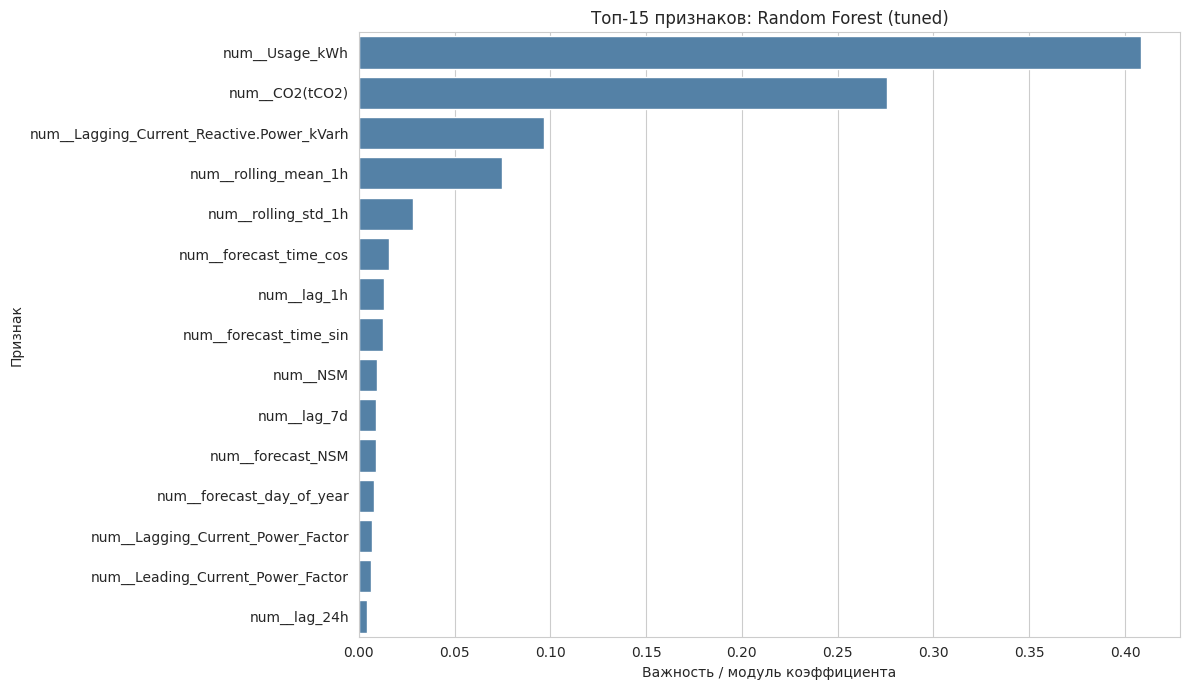

In [65]:
# Встроенная важность рассчитывается для выбранной по MAE модели.
# У Random Forest Pipeline признаки после One-Hot Encoding получают технические имена.
importance_values = None
importance_names = None
importance_method = None

if best_model_name == 'Random Forest (tuned)':
    fitted_preprocessor = best_model_object.named_steps['preprocessor']
    fitted_estimator = best_model_object.named_steps['model']
    importance_names = fitted_preprocessor.get_feature_names_out()
    importance_values = fitted_estimator.feature_importances_
    importance_method = 'Важность признаков Random Forest (суммарное снижение неоднородности в деревьях)'
elif best_model_name in ['CatBoost (default)', 'CatBoost (Optuna)', 'CatBoost (без CO₂)']:
    importance_names = best_model_features
    importance_values = best_model_object.feature_importances_
    importance_method = f'Встроенная важность {best_model_name}'
elif best_model_name == 'Linear Regression':
    fitted_preprocessor = best_model_object.named_steps['preprocessor']
    fitted_estimator = best_model_object.named_steps['model']
    importance_names = fitted_preprocessor.get_feature_names_out()
    importance_values = np.abs(fitted_estimator.coef_)
    importance_method = 'Модуль стандартизированных/преобразованных коэффициентов линейной регрессии (не tree importance)'
else:
    print('Для наивного прогноза важность признаков не определяется: модель не обучает параметры по признакам.')

if importance_values is not None:
    if len(importance_names) != len(importance_values):
        raise ValueError('Число имён признаков не совпало с числом значений важности.')
    feature_importance = pd.DataFrame({
        'Feature': importance_names,
        'Importance': importance_values
    }).sort_values('Importance', ascending=False)

    print(f'Топ-15 признаков выбранной модели: {best_model_name}')
    print('Метод интерпретации:', importance_method)
    display(feature_importance.head(15).round(4))

    plt.figure(figsize=(12, 7))
    sns.barplot(data=feature_importance.head(15), x='Importance', y='Feature', color='steelblue')
    plt.title(f'Топ-15 признаков: {best_model_name}')
    plt.xlabel('Важность / модуль коэффициента')
    plt.ylabel('Признак')
    plt.tight_layout()
    plt.show()

In [66]:
# Ручной permutation importance для выбранной модели.
# Используем одинаковый небольшой фрагмент теста для контроля времени расчёта.
if best_model_object is None:
    print('Permutation importance не применяется к наивному прогнозу: у него нет обучаемых признаков.')
else:
    perm_size = min(400, len(X_test))
    perm_idx = np.linspace(0, len(X_test) - 1, perm_size, dtype=int)
    X_perm = X_test.iloc[perm_idx][best_model_features].copy()
    y_perm = y_test.iloc[perm_idx].copy()

    baseline_perm_mae = mean_absolute_error(y_perm, best_model_object.predict(X_perm))
    rng = np.random.default_rng(SEED)
    permutation_rows = []
    for feature in best_model_features:
        increases = []
        for repeat in range(2):
            X_shuffled = X_perm.copy()
            X_shuffled[feature] = rng.permutation(X_shuffled[feature].to_numpy())
            shuffled_mae = mean_absolute_error(y_perm, best_model_object.predict(X_shuffled))
            increases.append(shuffled_mae - baseline_perm_mae)
        permutation_rows.append({
            'Признак': feature,
            'Рост MAE при перемешивании': float(np.mean(increases)),
            'Стандартное отклонение': float(np.std(increases))
        })

    permutation_table = pd.DataFrame(permutation_rows).sort_values(
        'Рост MAE при перемешивании', ascending=False
    )
    display(permutation_table.head(15).round(4))

,Признак,Рост MAE при перемешивании,Стандартное отклонение
0,Usage_kWh,14.4289,0.1789
3,CO2(tCO2),5.8181,0.0358
18,forecast_time_cos,3.2978,0.2521
21,rolling_mean_1h,1.2465,0.0858
23,lag_1h,1.1226,0.0575
1,Lagging_Current_Reactive.Power_kVarh,0.7923,0.0060
22,rolling_std_1h,0.4517,0.0314
6,NSM,0.3999,0.0388
17,forecast_time_sin,0.3675,0.0683
16,forecast_NSM,0.3079,0.0245


### Вывод по шагу 38 — прогноз сильнее всего опирается на текущее потребление и CO₂

Для выбранного Random Forest встроенная важность признаков распределилась следующим образом:

| Признак | Встроенная важность |
|---|---:|
| Текущий `Usage_kWh` | **0,4083** |
| `CO2(tCO2)` | **0,2757** |
| Отстающая реактивная энергия | **0,0966** |
| `rolling_mean_1h` | **0,0748** |
| `rolling_std_1h` | **0,0281** |

Первые два признака дают около **68,4%** суммарной встроенной важности, а первые пять — около **88,4%**. Это означает, что в структуре деревьев Random Forest особенно часто используются текущее потребление и CO₂, а также показатели электрического режима и недавней истории.

Permutation importance проверяет другой вопрос: насколько увеличивается MAE, если перемешать значения одного признака в выборке. На 400 равномерно выбранных тестовых наблюдениях наибольший рост MAE наблюдался при перемешивании `Usage_kWh` (**+14,429 кВт·ч**), затем CO₂ (**+5,818**), `forecast_time_cos` (**+3,298**), `rolling_mean_1h` (**+1,246**) и `lag_1h` (**+1,122**).

Эти два рейтинга не обязаны совпадать: встроенная важность описывает внутренние разбиения деревьев, permutation importance — ухудшение прогноза при разрушении информации признака. Коррелирующие признаки могут частично заменять друг друга. Кроме того, permutation importance рассчитана на подвыборке из 400 точек и двух повторениях, поэтому её следует считать диагностикой, а не точной универсальной оценкой.

**Важно:** высокая важность не доказывает причинное влияние. Например, из того, что CO₂ помогает прогнозу в данном наборе, не следует, что изменение CO₂ само по себе изменит потребление энергии.

## Шаг 39. Итоговые результаты, ограничения и дальнейшие улучшения

Сводим вместе качество, сильные стороны и ограничения. В итоговом выводе отдельно указываем, что было обнаружено в данных, как построена модель, чем подтверждается корректность эксперимента и где модель остаётся менее надёжной. Не называем прогноз экономией денег: финансовый эффект в этом ноутбуке не рассчитывался.

In [67]:
best_test_improvement = (m_naive[0]-best_model_mae)/m_naive[0]*100
summary_values = pd.DataFrame([
    ('Выбранная модель по CV',best_model_name),
    ('Средняя MAE CV',f"{cv_best_row['MAE_mean']:.3f} ± {cv_best_row['MAE_std']:.3f} кВт·ч"),
    ('MAE на тесте',f'{best_model_mae:.3f} кВт·ч'),
    ('RMSE на тесте',f"{float(best_model_row['RMSE']):.3f} кВт·ч"),
    ('R² на тесте',f"{float(best_model_row['R2']):.3f}"),
    ('Улучшение MAE относительно naive',f'{best_test_improvement:.1f}%'),
    ('MAE выше порога P90 обучающей выборки',f'{peak_mae:.3f} кВт·ч'),
    ('Отношение MAE пиков к общей MAE',f'{peak_error_ratio:.2f}×'),
    ('Bias на пиках',f'{peak_bias:.3f} кВт·ч')
],columns=['Показатель','Результат'])
display(summary_values)

,Показатель,Результат
0,Выбранная модель по CV,Random Forest (tuned)
1,Средняя MAE CV,5.356 ± 0.451 кВт·ч
2,MAE на тесте,4.102 кВт·ч
3,RMSE на тесте,8.668 кВт·ч
4,R² на тесте,0.924
5,Улучшение MAE относительно naive,24.6%
6,MAE выше порога P90 обучающей выборки,17.520 кВт·ч
7,Отношение MAE пиков к общей MAE,4.27×
8,Bias на пиках,15.477 кВт·ч


### Итоговый вывод по исследованию

#### 1. Что было сделано

Построен воспроизводимый pipeline прогноза `Usage_kWh` на следующий 15-минутный интервал. Исходные временные метки проверены и восстановлены; данные исследованы по распределению, календарным профилям, корреляциям и аномальным значениям. Для модели сформированы календарные, лаговые и скользящие признаки. Сравнивались наивный прогноз, линейная регрессия, Random Forest и CatBoost.

#### 2. Какая модель выбрана и что показывают метрики

| Показатель | Результат |
|---|---:|
| Выбор по временной CV | **Random Forest (tuned)** |
| Средняя MAE CV | **5,356 ± 0,451 кВт·ч** |
| MAE на тесте | **4,102 кВт·ч** |
| RMSE на тесте | **8,668 кВт·ч** |
| R² на тесте | **0,924** |
| Улучшение MAE к наивному прогнозу | **24,6%** |

MAE 4,102 кВт·ч означает, что на тестовом периоде средний модуль отклонения прогноза от факта составляет около 4,1 кВт·ч за 15-минутный интервал. RMSE заметно выше MAE, следовательно, отдельные крупные промахи имеют существенное влияние. R² = 0,924 характеризует высокую объяснённую долю изменчивости относительно постоянного среднего прогноза; это не «92,4% точности».

#### 3. Главное ограничение — пиковые нагрузки

Для тестовых наблюдений выше порога P90, рассчитанного на train, MAE составляет **17,52 кВт·ч** — в **4,27 раза** выше общей тестовой MAE. Положительный bias **+15,48 кВт·ч** означает средний недопрогноз на этом сегменте. Значит, модель уже хорошо описывает общий режим, но хуже реагирует на наиболее высокие нагрузки.

#### 4. Ограничения исследования

- Использован набор одного предприятия за один календарный год; перенос на другой завод или период требует новой проверки.
- Нет идентификаторов конкретного оборудования и производственных событий, поэтому нельзя доказать причину пиков.
- Optuna выполнена всего в двух испытаниях, Random Forest настраивался по двум наборам параметров; гиперпараметры не являются исчерпывающе оптимальными.
- Временная кросс-валидация включала два фолда в выделенном блоке train; для более сильного вывода стоит увеличить число фолдов и проверить дополнительные временные окна.
- Полезность CO₂ и категориальных признаков зависит от их доступности и стабильности при реальном внедрении.

#### 5. Что логично улучшить далее

Расширить временную кросс-валидацию и поиск параметров; отдельно оптимизировать прогноз высоких нагрузок; проверить более длинные горизонты (30 минут, 1 час, 4 часа); повторить оценку на новых временных периодах; при наличии технологических журналов связать пики с режимами оборудования.

> **Итог:** на предоставленном наборе построена и проверена модель прогноза следующего 15-минутного интервала. Результат подтверждён временной валидацией и отложенным тестом, но высокая средняя точность не устраняет проблему пиковых нагрузок. Ноутбук не рассчитывает денежную экономию и не доказывает, что модель уже может автоматически управлять производством.